In [1]:
import pandas as pd 
import numpy as np 
import MetaTrader5 as mt5
from datetime import datetime, timezone
from pathlib import Path

# Pipeline configurations

In [2]:
# Assets configuration

assets = ['EURUSDm','USDCADm','USDJPYm','GBPUSDm','USDCHFm','EURCADm',
          'EURCHFm','EURGBPm','EURJPYm','UKOILm','USOILm','XAUUSDm', 'XAGUSDm']

In [3]:
# Candle timeframe

timeframe = mt5.TIMEFRAME_D1

In [4]:
# Defining initial date to get data

initial_date = datetime(2010, 1, 1, tzinfo=timezone.utc)

# Defining final date to finishing proccess

final_date = datetime.now(timezone.utc)

In [5]:
# Storage and get data function

def data_storage(asset):
    
    # Search for candles on timeframe defined

    rates = mt5.copy_rates_range(asset,
                                 timeframe,
                                 initial_date,
                                 final_date)
    
    # If have a error, break the proccess

    if rates is None or len(rates) == 0:
        print(f'Fail to get data asset {asset}: {mt5.last_error()}')
        return None
    
    # Convert get data in dataframe

    df = pd.DataFrame(rates)

    # Convert the timestamps Unix to datetime with timezone UTC

    df['time'] = pd.to_datetime(df['time'], unit='s', utc=True)

    # Order olders candles to new candles

    df = df.sort_values('time')

    # Remove evenctually register with duplicate timestamp

    df = df.drop_duplicates(subset='time', keep='last')

    # Verify if essential values have a data

    essential_colums = ['time','open','high','low',
                        'close']
    
    if df[essential_colums].isna().any().any():
        raise ValueError(f'{asset}: there is NaN values presents on dataframe')
    
    # Verify if asset price are positive

    if (df[['open','high','low','close']] <= 0).any().any():
        raise ValueError(f'{asset}: there is negative price on dataframe')
    
    # Remove last candle, because most be in close processing

    if not df.empty:
        df = df.iloc[:-1].copy()

    # Adds the asset name to identify the origin of data

    df['symbol'] = asset 

    # Return validated dataframe

    return df

# Create a pipeline to extract Macro indicators

In [6]:
# Read macro indicators of Euro zone, USA, Canada, Switzerland, England and Japan central banks

canada = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\canada_macro.csv',
                     sep=',', encoding='utf8')
euro_zone = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\euro_macro.csv',
                        sep=',', encoding='utf8')
japan = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\japan_macro.csv',
                    sep=',', encoding='utf8')
switz = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\switzerland_macro.csv',
                    sep=',', encoding='utf8')
england = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\uk_macro.csv',
                    sep=',', encoding='utf8')
usa = pd.read_csv(r'C:\\Christian_meus_estudos\\financial_market_quantitative_analyses\\pipeline_market\\storage\\usa_macro.csv',
                    sep=',', encoding='utf8')

In [7]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,NaN,NaN
1,1990-02-01,5.464481,NaN,NaN
2,1990-03-01,5.298913,NaN,0.961690
3,1990-04-01,5.013550,NaN,NaN
4,1990-05-01,4.423592,NaN,NaN
...,...,...,...,...
436,2026-05-01,3.225806,2.25,NaN
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,NaN
439,2026-08-01,3.033981,2.25,NaN


In [8]:
euro_zone

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,NaN,NaN,NaN
1,1990-02-01,NaN,NaN,NaN
2,1990-03-01,NaN,NaN,NaN
3,1990-04-01,NaN,NaN,NaN
4,1990-05-01,NaN,NaN,NaN
...,...,...,...,...
436,2026-05-01,3.171269,2.15,NaN
437,2026-06-01,2.752843,2.40,0.632995
438,2026-07-01,2.941470,2.40,NaN
439,2026-08-01,3.246042,2.40,NaN


In [9]:
japan

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,3.280840,4.25,NaN
1,1990-02-01,3.820817,4.25,NaN
2,1990-03-01,3.669724,5.25,NaN
3,1990-04-01,2.574002,5.25,NaN
4,1990-05-01,2.560820,5.25,NaN
...,...,...,...,...
436,2026-05-01,1.500000,0.75,NaN
437,2026-06-01,1.701701,1.00,0.360456
438,2026-07-01,1.898101,1.00,NaN
439,2026-08-01,NaN,1.00,NaN


In [10]:
switz

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,NaN,NaN,NaN
1,1990-02-01,NaN,NaN,NaN
2,1990-03-01,NaN,NaN,NaN
3,1990-04-01,NaN,NaN,NaN
4,1990-05-01,NaN,NaN,NaN
...,...,...,...,...
436,2026-05-01,0.879648,0.0,NaN
437,2026-06-01,0.727962,0.0,1.884751
438,2026-07-01,0.675810,0.0,NaN
439,2026-08-01,0.915332,0.0,NaN


In [11]:
england

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.511811,14.875,NaN
1,1990-02-01,5.882353,14.875,NaN
2,1990-03-01,5.859375,14.875,0.514596
3,1990-04-01,6.358382,14.875,NaN
4,1990-05-01,6.704981,14.875,NaN
...,...,...,...,...
436,2026-05-01,2.890173,3.750,NaN
437,2026-06-01,2.591793,3.750,0.532607
438,2026-07-01,2.805755,3.750,NaN
439,2026-08-01,3.086863,3.750,NaN


In [12]:
usa 

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.202312,8.25,NaN
1,1990-02-01,5.263158,8.25,NaN
2,1990-03-01,5.233034,8.25,1.092882
3,1990-04-01,4.711617,8.25,NaN
4,1990-05-01,4.361874,8.25,NaN
...,...,...,...,...
436,2026-05-01,4.248674,3.75,NaN
437,2026-06-01,3.531425,3.75,0.550490
438,2026-07-01,3.364825,3.75,NaN
439,2026-08-01,3.396548,3.75,NaN


# Data frame processing and data preparation for macroeconomic analysis.

In [13]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,NaN,NaN
1,1990-02-01,5.464481,NaN,NaN
2,1990-03-01,5.298913,NaN,0.961690
3,1990-04-01,5.013550,NaN,NaN
4,1990-05-01,4.423592,NaN,NaN
...,...,...,...,...
436,2026-05-01,3.225806,2.25,NaN
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,NaN
439,2026-08-01,3.033981,2.25,NaN


In [14]:
"""
    Here, replacing the data with the median is neither the best nor the recommended approach, 
    but since extracting macroeconomic data generally requires an API key from reliable paid sites like Bloomberg,
    And at the moment I don't have such resources for a portfolio project, 
    I decided to extract the data directly from the official central bank websites of each country in question 
    and replace it with the median values ​​to simplify the project 
    and prepare the model for financial market analysis and forecasting, more specifically, the forex market.
"""

def prepare_df_macro(df):
    
    # Copy df

    df = df.copy()

    # Replacing NaN values ​​with the median

    for i in df.columns:
        if i == 'reference_date':
            continue

        df[i] = df[i].fillna(df[i].median())

    # Return df

    return df

In [15]:
canada.isna().sum()

reference_date           0
inflation_yoy            1
central_bank_rate      231
real_gdp_growth_qoq    295
dtype: int64

In [16]:
canada = prepare_df_macro(canada)

In [17]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,1.00,0.636564
1,1990-02-01,5.464481,1.00,0.636564
2,1990-03-01,5.298913,1.00,0.961690
3,1990-04-01,5.013550,1.00,0.636564
4,1990-05-01,4.423592,1.00,0.636564
...,...,...,...,...
436,2026-05-01,3.225806,2.25,0.636564
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,0.636564
439,2026-08-01,3.033981,2.25,0.636564


In [18]:
canada.isna().sum()

reference_date         0
inflation_yoy          0
central_bank_rate      0
real_gdp_growth_qoq    0
dtype: int64

In [19]:
euro_zone = prepare_df_macro(euro_zone)
japan = prepare_df_macro(japan)
switz = prepare_df_macro(switz)
england = prepare_df_macro(england)
usa = prepare_df_macro(usa)

# A very important observation here:

In a real investment environment, for data that is not obtained and comes in NaN format, the best approach would be to exclude the NaN rows or seek another data source.

However, as I mentioned, in this market, the best data sources are paid, and for a portfolio project where I handle everything from the initial pipeline process, data extraction, and preparation, there is no need to invest financially in such a project or prepare a mega-structure for something that I may not even execute in the financial market investing real money; it's just study and learning.

But I'm just justifying the practice I adopted of replacing NaN values ​​with the median to facilitate the development of econometric models, because the problem with consulting central bank APIs is that many series are discontinued, many data points are not filled in correctly, generating gaps, etc.

The best way to decide between filling in with the mean, median, or deleting those NaN rows depends on your business rules and how sensitive your model will be to the data.

In [20]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,1.00,0.636564
1,1990-02-01,5.464481,1.00,0.636564
2,1990-03-01,5.298913,1.00,0.961690
3,1990-04-01,5.013550,1.00,0.636564
4,1990-05-01,4.423592,1.00,0.636564
...,...,...,...,...
436,2026-05-01,3.225806,2.25,0.636564
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,0.636564
439,2026-08-01,3.033981,2.25,0.636564


# Returning to extracting data from the financial market with MT5

In [21]:
# Executing pipeline MT5

def data_storage(asset):

    # Collect market data from MT5
    rates = mt5.copy_rates_range(
        asset, timeframe, initial_date, final_date
    )

    if rates is None or len(rates) == 0:
        raise RuntimeError(
            f"Failed to collect {asset}: {mt5.last_error()}"
        )

    # Create DataFrame
    df = pd.DataFrame(rates)

    # Convert timestamps to UTC
    df["time"] = pd.to_datetime(
        df["time"], unit="s", utc=True
    )

    # Sort data and remove duplicated timestamps
    df = (
        df.sort_values("time")
        .drop_duplicates(subset="time", keep="last")
        .reset_index(drop=True)
    )

    # Validate price columns
    price_cols = ["open", "high", "low", "close"]

    if df[price_cols].isna().any().any():
        raise ValueError(f"{asset}: missing prices.")

    if not np.isfinite(df[price_cols].to_numpy()).all():
        raise ValueError(f"{asset}: invalid prices.")

    if (df[price_cols] <= 0).any().any():
        raise ValueError(f"{asset}: non-positive prices.")

    # Remove the current daily candle if it may still be forming
    if (
        timeframe == mt5.TIMEFRAME_D1
        and not df.empty
        and df["time"].iloc[-1].date()
        == datetime.now(timezone.utc).date()
    ):
        df = df.iloc[:-1].copy()

    # Identify the asset
    df["symbol"] = asset

    return df.reset_index(drop=True)


def main():

    # Initialize MetaTrader 5 connection
    if not mt5.initialize():
        raise RuntimeError(
            f"Not possible to connect to MT5: {mt5.last_error()}"
        )

    try:

        # Confirm terminal connection
        terminal = mt5.terminal_info()

        print("MetaTrader5 connected!")
        print(f"Terminal available: {terminal is not None}")

        # Store collected DataFrames
        dataframes = {}

        # Collect data for each asset
        for asset in assets:

            print(f"Extracting data for {asset}")

            # Select asset in MT5
            if not mt5.symbol_select(asset, True):
                print(f"Asset unavailable: {asset}")
                continue

            try:

                # Collect market data
                df = data_storage(asset)

                # Store DataFrame
                dataframes[asset] = df

                print(f"{asset}: {len(df)} candles collected.")

            except Exception as error:
                print(f"Error collecting {asset}: {error}")

        return dataframes

    finally:

        # Close MT5 connection
        mt5.shutdown()
        print("\nMetaTrader5 connection closed.")


# Execute pipeline
dataframes = main()

MetaTrader5 connected!
Terminal available: True
Extracting data for EURUSDm
EURUSDm: 3941 candles collected.
Extracting data for USDCADm
USDCADm: 1556 candles collected.
Extracting data for USDJPYm
USDJPYm: 1556 candles collected.
Extracting data for GBPUSDm
GBPUSDm: 3941 candles collected.
Extracting data for USDCHFm
USDCHFm: 1556 candles collected.
Extracting data for EURCADm
EURCADm: 1556 candles collected.
Extracting data for EURCHFm
EURCHFm: 1556 candles collected.
Extracting data for EURGBPm
EURGBPm: 1556 candles collected.
Extracting data for EURJPYm
EURJPYm: 1556 candles collected.
Extracting data for UKOILm
UKOILm: 1284 candles collected.
Extracting data for USOILm
USOILm: 1548 candles collected.
Extracting data for XAUUSDm
XAUUSDm: 1548 candles collected.
Extracting data for XAGUSDm
XAGUSDm: 1548 candles collected.

MetaTrader5 connection closed.


In [22]:
# The MT5 pipeline only runs if the file is started.

if __name__ == '__main__':
    dataframes = main()

MetaTrader5 connected!
Terminal available: True
Extracting data for EURUSDm
EURUSDm: 3941 candles collected.
Extracting data for USDCADm
USDCADm: 1556 candles collected.
Extracting data for USDJPYm
USDJPYm: 1556 candles collected.
Extracting data for GBPUSDm
GBPUSDm: 3941 candles collected.
Extracting data for USDCHFm
USDCHFm: 1556 candles collected.
Extracting data for EURCADm
EURCADm: 1556 candles collected.
Extracting data for EURCHFm
EURCHFm: 1556 candles collected.
Extracting data for EURGBPm
EURGBPm: 1556 candles collected.
Extracting data for EURJPYm
EURJPYm: 1556 candles collected.
Extracting data for UKOILm
UKOILm: 1284 candles collected.
Extracting data for USOILm
USOILm: 1548 candles collected.
Extracting data for XAUUSDm
XAUUSDm: 1548 candles collected.
Extracting data for XAGUSDm
XAGUSDm: 1548 candles collected.

MetaTrader5 connection closed.


In [23]:
eurusd = dataframes["EURUSDm"]

In [24]:
eurusd

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2014-01-14 00:00:00+00:00,1.36669,1.36983,1.36485,1.36661,58248,0,0,EURUSDm
1,2014-01-15 00:00:00+00:00,1.36665,1.36723,1.35807,1.35986,60319,0,0,EURUSDm
2,2014-01-16 00:00:00+00:00,1.35990,1.36487,1.35827,1.36145,72629,0,0,EURUSDm
3,2014-01-17 00:00:00+00:00,1.36129,1.36205,1.35166,1.35382,64588,0,0,EURUSDm
4,2014-01-19 00:00:00+00:00,1.35365,1.35396,1.35238,1.35264,1682,0,0,EURUSDm
...,...,...,...,...,...,...,...,...,...
3936,2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm
3937,2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm
3938,2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm
3939,2026-10-16 00:00:00+00:00,1.12124,1.12692,1.12077,1.12388,32842,8,0,EURUSDm


In [25]:
eurcad = dataframes["EURCADm"]
eurchf = dataframes["EURCHFm"]
eurgbp = dataframes["EURGBPm"]
eurjpy = dataframes["EURJPYm"]

usdcad = dataframes["USDCADm"]
usdchf = dataframes["USDCHFm"]
usdjpy = dataframes["USDJPYm"]

wti = dataframes["USOILm"]
brent = dataframes["UKOILm"]
gold = dataframes["XAUUSDm"]

gbpusd = dataframes["GBPUSDm"]
silver = dataframes["XAGUSDm"]

In [26]:
eurcad

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1.43125,1.43267,1.43125,1.43235,425,20,0,EURCADm
1,2021-10-28 00:00:00+00:00,1.43339,1.44342,1.43088,1.44238,23728,20,0,EURCADm
2,2021-10-29 00:00:00+00:00,1.44240,1.44415,1.42951,1.43132,30462,20,0,EURCADm
3,2021-10-31 00:00:00+00:00,1.43096,1.43191,1.43069,1.43102,1187,20,0,EURCADm
4,2021-11-01 00:00:00+00:00,1.43099,1.43616,1.42959,1.43527,22533,20,0,EURCADm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,1.59354,1.59619,1.58960,1.59241,19712,15,0,EURCADm
1552,2026-10-14 00:00:00+00:00,1.59238,1.59250,1.58612,1.59086,27806,15,0,EURCADm
1553,2026-10-15 00:00:00+00:00,1.59084,1.59608,1.58933,1.59141,33480,15,0,EURCADm
1554,2026-10-16 00:00:00+00:00,1.59140,1.59456,1.58791,1.58886,24066,15,0,EURCADm


In [27]:
eurchf

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1.06492,1.06492,1.06476,1.06492,70,29,0,EURCHFm
1,2021-10-28 00:00:00+00:00,1.06443,1.06698,1.06350,1.06497,9207,29,0,EURCHFm
2,2021-10-29 00:00:00+00:00,1.06499,1.06542,1.05687,1.05812,10830,29,0,EURCHFm
3,2021-10-31 00:00:00+00:00,1.05726,1.05883,1.05722,1.05863,832,29,0,EURCHFm
4,2021-11-01 00:00:00+00:00,1.05864,1.06028,1.05339,1.05473,9813,29,0,EURCHFm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,0.93078,0.93270,0.93055,0.93270,8753,16,0,EURCHFm
1552,2026-10-14 00:00:00+00:00,0.93268,0.93341,0.93039,0.93103,13154,16,0,EURCHFm
1553,2026-10-15 00:00:00+00:00,0.93105,0.93145,0.92692,0.92809,17408,16,0,EURCHFm
1554,2026-10-16 00:00:00+00:00,0.92806,0.92890,0.92484,0.92603,14085,16,0,EURCHFm


In [28]:
eurgbp

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,0.84414,0.84421,0.84406,0.84414,115,16,0,EURGBPm
1,2021-10-28 00:00:00+00:00,0.84274,0.84751,0.84221,0.84656,10785,16,0,EURGBPm
2,2021-10-29 00:00:00+00:00,0.84657,0.84720,0.84325,0.84428,14942,16,0,EURGBPm
3,2021-10-31 00:00:00+00:00,0.84431,0.84483,0.84416,0.84452,635,16,0,EURGBPm
4,2021-11-01 00:00:00+00:00,0.84454,0.84987,0.84417,0.84940,12577,16,0,EURGBPm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,0.84476,0.84572,0.84431,0.84485,5924,13,0,EURGBPm
1552,2026-10-14 00:00:00+00:00,0.84484,0.84622,0.84262,0.84610,9601,13,0,EURGBPm
1553,2026-10-15 00:00:00+00:00,0.84608,0.84771,0.84455,0.84485,11127,13,0,EURGBPm
1554,2026-10-16 00:00:00+00:00,0.84487,0.84500,0.84182,0.84315,8409,13,0,EURGBPm


In [29]:
eurjpy

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,132.056,132.084,132.018,132.084,237,19,0,EURJPYm
1,2021-10-28 00:00:00+00:00,131.692,132.726,131.549,132.721,20494,19,0,EURJPYm
2,2021-10-29 00:00:00+00:00,132.723,132.909,131.599,131.808,28448,19,0,EURJPYm
3,2021-10-31 00:00:00+00:00,131.801,132.047,131.797,132.009,1575,19,0,EURJPYm
4,2021-11-01 00:00:00+00:00,132.011,132.436,131.788,132.336,23391,19,0,EURJPYm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,176.907,177.374,176.477,177.335,33980,16,0,EURJPYm
1552,2026-10-14 00:00:00+00:00,177.331,177.586,176.285,176.846,40469,16,0,EURJPYm
1553,2026-10-15 00:00:00+00:00,176.843,177.411,176.634,177.305,50785,16,0,EURJPYm
1554,2026-10-16 00:00:00+00:00,177.306,177.958,177.138,177.541,35813,16,0,EURJPYm


In [30]:
usdcad

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1.23239,1.23416,1.23239,1.23370,530,12,0,USDCADm
1,2021-10-28 00:00:00+00:00,1.23681,1.23727,1.23293,1.23465,23003,12,0,USDCADm
2,2021-10-29 00:00:00+00:00,1.23469,1.24075,1.23270,1.23798,33752,12,0,USDCADm
3,2021-10-31 00:00:00+00:00,1.23795,1.23856,1.23759,1.23828,605,22,0,USDCADm
4,2021-11-01 00:00:00+00:00,1.23833,1.24029,1.23510,1.23732,23179,12,0,USDCADm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,1.42799,1.42822,1.42030,1.42170,14001,14,0,USDCADm
1552,2026-10-14 00:00:00+00:00,1.42167,1.42992,1.41964,1.42128,20085,14,0,USDCADm
1553,2026-10-15 00:00:00+00:00,1.42125,1.42215,1.41689,1.41935,22131,14,0,USDCADm
1554,2026-10-16 00:00:00+00:00,1.41936,1.41982,1.41338,1.41377,16597,14,0,USDCADm


In [31]:
usdchf

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,0.91702,0.91739,0.91699,0.91728,239,10,0,USDCHFm
1,2021-10-28 00:00:00+00:00,0.91857,0.91942,0.91119,0.91168,22939,10,0,USDCHFm
2,2021-10-29 00:00:00+00:00,0.91169,0.91757,0.91018,0.91532,26238,10,0,USDCHFm
3,2021-10-31 00:00:00+00:00,0.91541,0.91628,0.91528,0.91612,454,15,0,USDCHFm
4,2021-11-01 00:00:00+00:00,0.91614,0.91710,0.90841,0.90933,20001,10,0,USDCHFm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,0.83405,0.83445,0.83128,0.83269,13549,13,0,USDCHFm
1552,2026-10-14 00:00:00+00:00,0.83267,0.83943,0.83156,0.83169,20693,13,0,USDCHFm
1553,2026-10-15 00:00:00+00:00,0.83167,0.83238,0.82642,0.82774,32046,13,0,USDCHFm
1554,2026-10-16 00:00:00+00:00,0.82771,0.82817,0.82175,0.82392,24218,13,0,USDCHFm


In [32]:
usdjpy

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,113.710,113.769,113.697,113.767,326,8,0,USDJPYm
1,2021-10-28 00:00:00+00:00,113.638,113.717,113.251,113.611,22194,8,0,USDJPYm
2,2021-10-29 00:00:00+00:00,113.613,114.092,113.389,113.978,32390,8,0,USDJPYm
3,2021-10-31 00:00:00+00:00,114.015,114.250,114.003,114.232,1135,11,0,USDJPYm
4,2021-11-01 00:00:00+00:00,114.235,114.440,113.911,114.088,26075,8,0,USDJPYm
...,...,...,...,...,...,...,...,...,...
1551,2026-10-13 00:00:00+00:00,158.526,158.527,157.827,158.316,44759,10,0,USDJPYm
1552,2026-10-14 00:00:00+00:00,158.314,158.946,157.876,157.977,50733,10,0,USDJPYm
1553,2026-10-15 00:00:00+00:00,157.975,158.242,157.543,158.135,72505,10,0,USDJPYm
1554,2026-10-16 00:00:00+00:00,158.132,158.336,157.689,157.979,48237,10,0,USDJPYm


In [33]:
brent

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,83.883,83.883,83.581,83.676,534,96,0,UKOILm
1,2021-10-28 00:00:00+00:00,83.059,83.825,81.906,83.771,18350,92,0,UKOILm
2,2021-10-29 00:00:00+00:00,83.491,84.059,82.374,83.480,25574,94,0,UKOILm
3,2021-11-01 00:00:00+00:00,83.110,84.824,82.826,84.205,22001,93,0,UKOILm
4,2021-11-02 00:00:00+00:00,84.194,84.862,83.435,83.685,23644,93,0,UKOILm
...,...,...,...,...,...,...,...,...,...
1279,2026-10-12 00:00:00+00:00,101.986,105.502,100.633,104.350,168008,13,0,UKOILm
1280,2026-10-13 00:00:00+00:00,104.054,105.136,102.649,104.785,120995,13,0,UKOILm
1281,2026-10-14 00:00:00+00:00,104.569,105.443,103.702,104.502,127960,13,0,UKOILm
1282,2026-10-15 00:00:00+00:00,103.955,104.662,101.949,104.050,148803,13,0,UKOILm


In [34]:
silver

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,24.100,24.112,24.085,24.087,157,54,0,XAGUSDm
1,2021-10-28 00:00:00+00:00,24.084,24.220,23.936,24.039,9774,54,0,XAGUSDm
2,2021-10-29 00:00:00+00:00,24.037,24.054,23.633,23.862,15256,54,0,XAGUSDm
3,2021-10-31 00:00:00+00:00,23.829,23.832,23.722,23.750,416,54,0,XAGUSDm
4,2021-11-01 00:00:00+00:00,23.752,24.071,23.724,23.996,11764,54,0,XAGUSDm
...,...,...,...,...,...,...,...,...,...
1543,2026-10-13 00:00:00+00:00,60.245,60.719,58.888,58.982,61447,25,0,XAGUSDm
1544,2026-10-14 00:00:00+00:00,58.979,59.363,55.380,55.716,83890,25,0,XAGUSDm
1545,2026-10-15 00:00:00+00:00,55.718,57.521,55.687,57.078,68296,25,0,XAGUSDm
1546,2026-10-16 00:00:00+00:00,57.073,57.970,56.874,56.975,63580,25,0,XAGUSDm


In [35]:
gold

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,1795.864,1797.361,1795.695,1796.984,1275,200,0,XAUUSDm
1,2021-10-28 00:00:00+00:00,1799.738,1810.380,1792.306,1799.575,76894,200,0,XAUUSDm
2,2021-10-29 00:00:00+00:00,1799.559,1799.944,1771.896,1783.296,108247,200,0,XAUUSDm
3,2021-10-31 00:00:00+00:00,1783.269,1783.269,1779.055,1780.026,3100,200,0,XAUUSDm
4,2021-11-01 00:00:00+00:00,1780.020,1795.750,1779.988,1792.047,77556,200,0,XAUUSDm
...,...,...,...,...,...,...,...,...,...
1543,2026-10-13 00:00:00+00:00,4170.736,4200.391,4146.720,4154.941,217560,240,0,XAUUSDm
1544,2026-10-14 00:00:00+00:00,4155.136,4170.519,4073.195,4111.850,316484,240,0,XAUUSDm
1545,2026-10-15 00:00:00+00:00,4111.885,4177.440,4111.083,4156.128,269371,240,0,XAUUSDm
1546,2026-10-16 00:00:00+00:00,4155.935,4198.812,4147.115,4165.147,237118,240,0,XAUUSDm


In [36]:
wti

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2021-10-27 00:00:00+00:00,82.303,82.303,81.959,82.084,613,86,0,USOILm
1,2021-10-28 00:00:00+00:00,81.506,82.608,80.263,82.086,21695,86,0,USOILm
2,2021-10-29 00:00:00+00:00,82.072,82.867,80.797,82.511,30606,86,0,USOILm
3,2021-10-31 00:00:00+00:00,82.197,82.306,81.871,82.094,1140,86,0,USOILm
4,2021-11-01 00:00:00+00:00,82.098,83.928,81.914,82.985,26539,86,0,USOILm
...,...,...,...,...,...,...,...,...,...
1543,2026-10-13 00:00:00+00:00,92.415,94.179,90.920,93.767,162591,20,0,USOILm
1544,2026-10-14 00:00:00+00:00,93.762,94.922,93.102,93.606,167289,20,0,USOILm
1545,2026-10-15 00:00:00+00:00,93.599,96.720,92.455,96.079,132759,20,0,USOILm
1546,2026-10-16 00:00:00+00:00,96.076,99.269,95.215,98.873,116778,20,0,USOILm


In [37]:
gbpusd

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2014-01-14 00:00:00+00:00,1.63878,1.64633,1.63669,1.64318,53646,0,0,GBPUSDm
1,2014-01-15 00:00:00+00:00,1.64325,1.64369,1.63222,1.63601,63863,0,0,GBPUSDm
2,2014-01-16 00:00:00+00:00,1.63612,1.63815,1.63124,1.63458,57297,0,0,GBPUSDm
3,2014-01-17 00:00:00+00:00,1.63445,1.64576,1.63088,1.64170,57879,0,0,GBPUSDm
4,2014-01-19 00:00:00+00:00,1.64167,1.64197,1.64091,1.64165,1954,0,0,GBPUSDm
...,...,...,...,...,...,...,...,...,...
3936,2026-10-13 00:00:00+00:00,1.32092,1.32588,1.32039,1.32568,32676,7,0,GBPUSDm
3937,2026-10-14 00:00:00+00:00,1.32565,1.32751,1.31364,1.32289,51418,4,0,GBPUSDm
3938,2026-10-15 00:00:00+00:00,1.32287,1.32780,1.32208,1.32700,58362,7,0,GBPUSDm
3939,2026-10-16 00:00:00+00:00,1.32698,1.33714,1.32673,1.33275,42656,10,0,GBPUSDm


In [38]:
import matplotlib.pyplot as plt 
from matplotlib import rcParams
rcParams['figure.figsize'] = 15,6

In [39]:
# Sort dataframe

def sort_df_forex(df):

    # Copy df 

    df = df.copy()

    # Sort df

    df.sort_values(by='time', inplace=True)

    # Index df

    df.set_index(df.time, inplace=True)

    # Return df

In [40]:
sort_df_forex(eurusd)
sort_df_forex(eurchf)
sort_df_forex(eurgbp)
sort_df_forex(eurjpy)
sort_df_forex(eurcad)
sort_df_forex(usdcad)
sort_df_forex(usdchf)
sort_df_forex(usdjpy)
sort_df_forex(silver)
sort_df_forex(gold)
sort_df_forex(wti)
sort_df_forex(brent)

In [41]:
eurusd

,time,open,high,low,close,tick_volume,spread,real_volume,symbol
0,2014-01-14 00:00:00+00:00,1.36669,1.36983,1.36485,1.36661,58248,0,0,EURUSDm
1,2014-01-15 00:00:00+00:00,1.36665,1.36723,1.35807,1.35986,60319,0,0,EURUSDm
2,2014-01-16 00:00:00+00:00,1.35990,1.36487,1.35827,1.36145,72629,0,0,EURUSDm
3,2014-01-17 00:00:00+00:00,1.36129,1.36205,1.35166,1.35382,64588,0,0,EURUSDm
4,2014-01-19 00:00:00+00:00,1.35365,1.35396,1.35238,1.35264,1682,0,0,EURUSDm
...,...,...,...,...,...,...,...,...,...
3936,2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm
3937,2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm
3938,2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm
3939,2026-10-16 00:00:00+00:00,1.12124,1.12692,1.12077,1.12388,32842,8,0,EURUSDm


In [42]:
def plot_lines_graph_forex(df):

    # Plot a line graph

    plt.plot(df.time, df.close, linewidth=0.85, color='red')
    plt.title('Price Close price behind over time')
    plt.xlabel('Time')
    plt.ylabel('Price')
    plt.grid(True)
    ax = plt.gca()
    ax.set_xticks(df.time[::300])
    plt.xticks(rotation=50)
    plt.show()

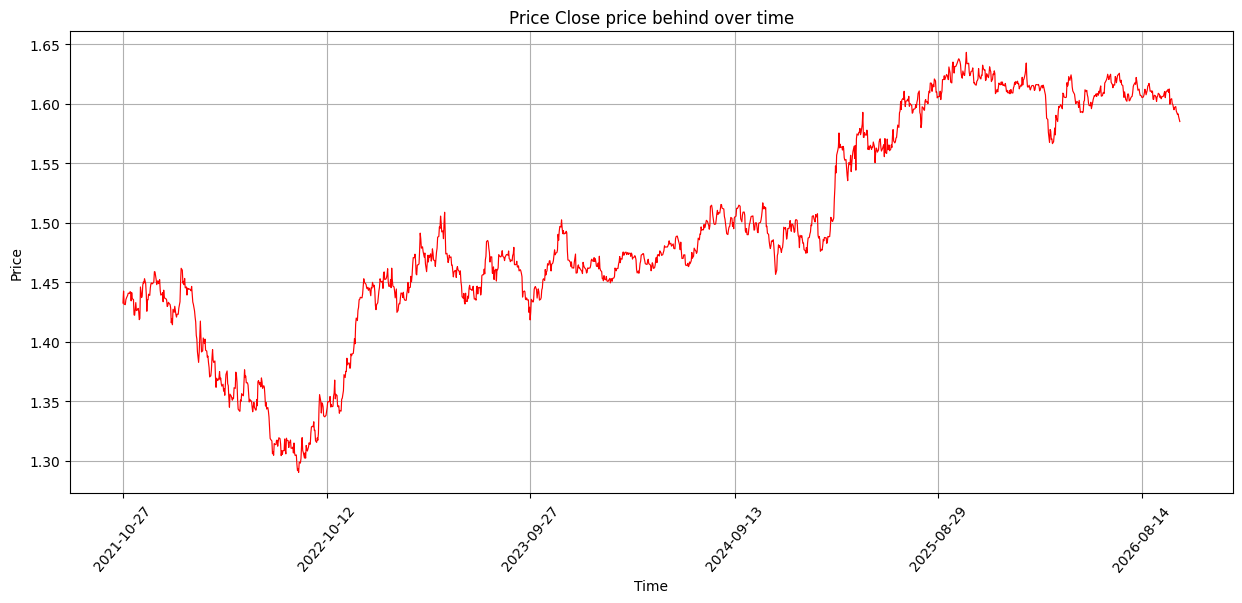

In [43]:
plot_lines_graph_forex(eurcad)

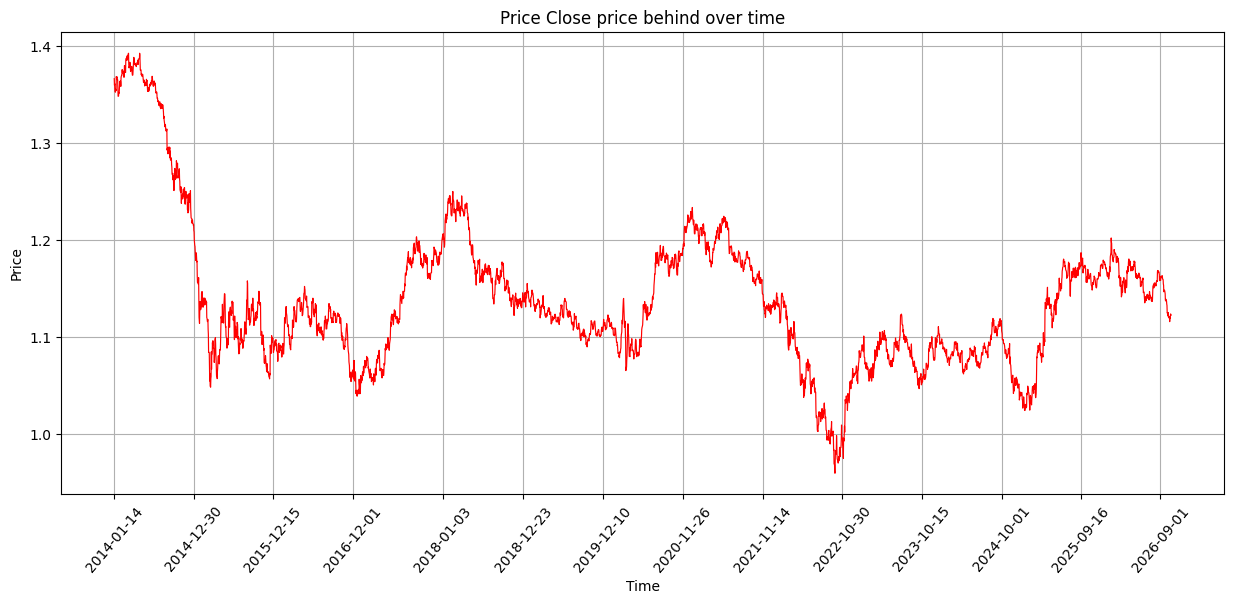

In [44]:
plot_lines_graph_forex(eurusd)

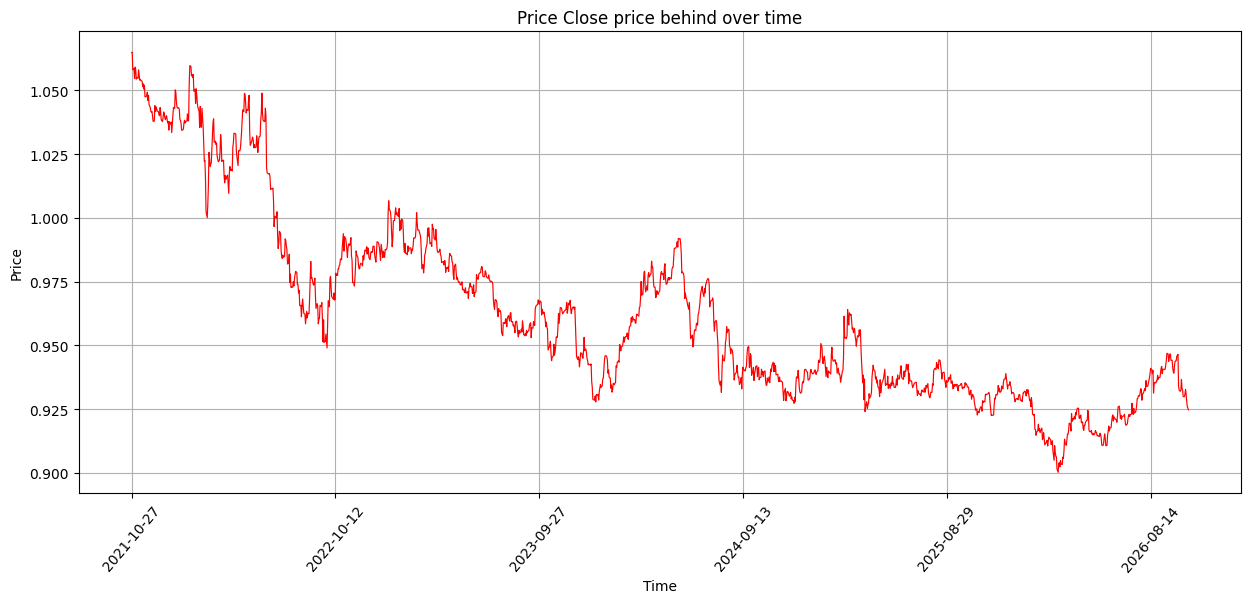

In [45]:
plot_lines_graph_forex(eurchf)

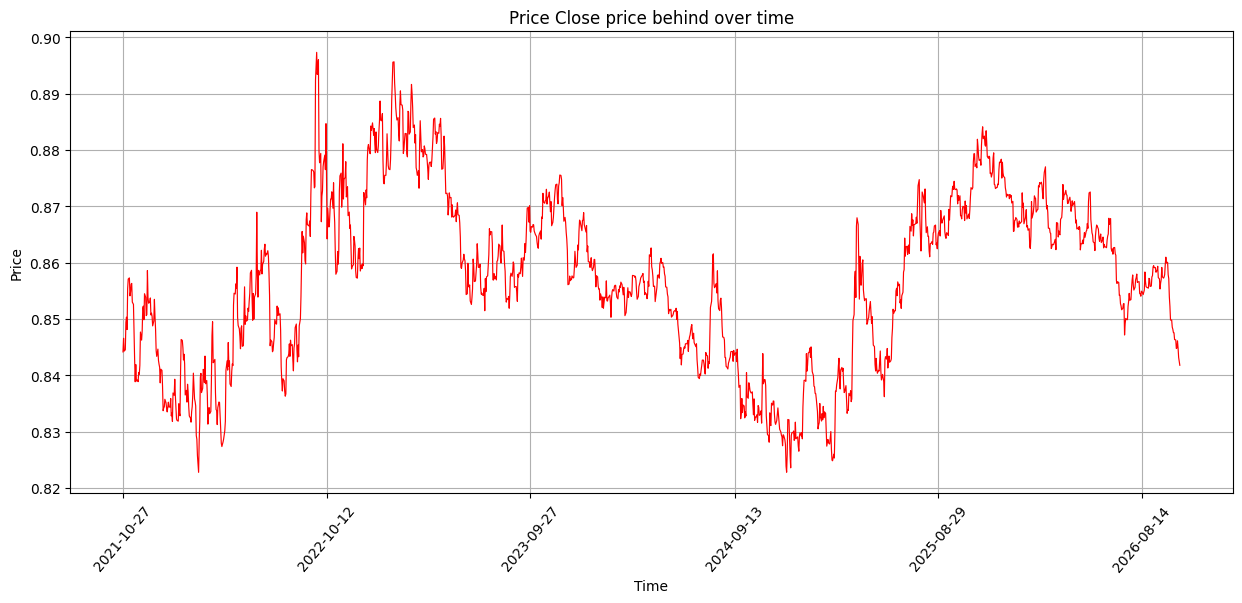

In [46]:
plot_lines_graph_forex(eurgbp)

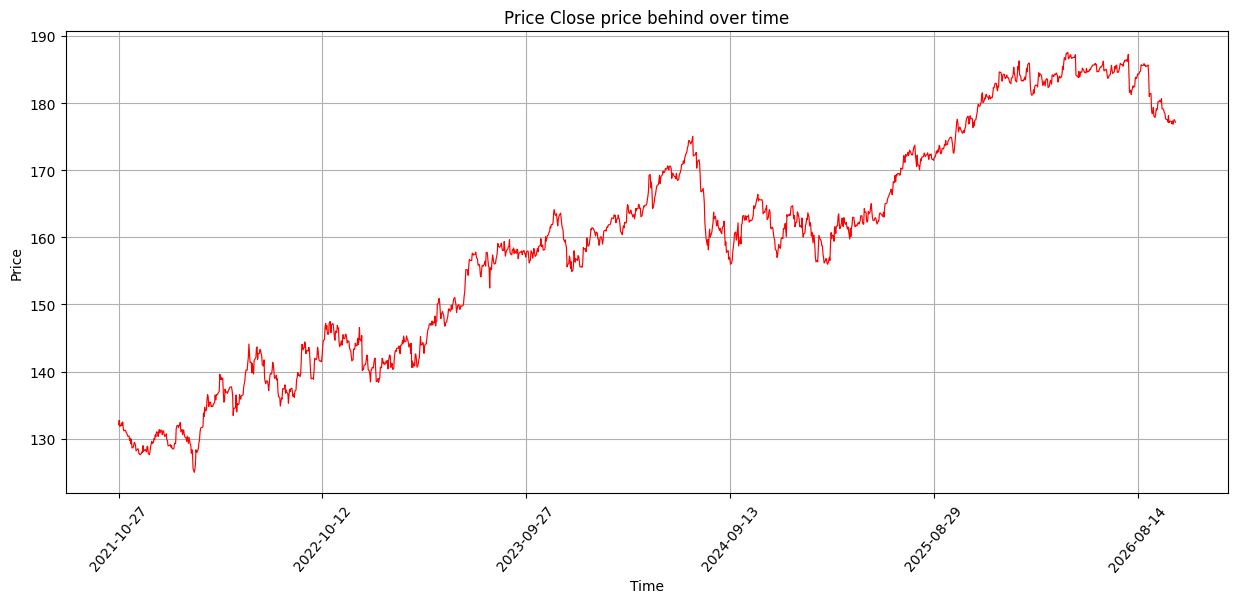

In [47]:
plot_lines_graph_forex(eurjpy)

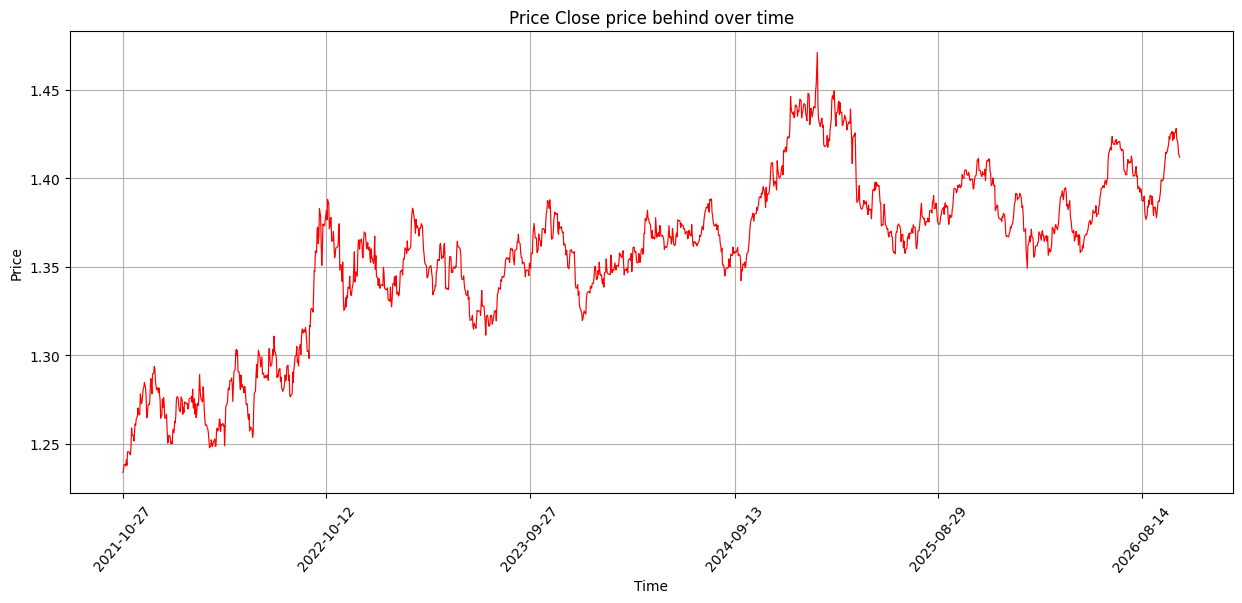

In [48]:
plot_lines_graph_forex(usdcad)

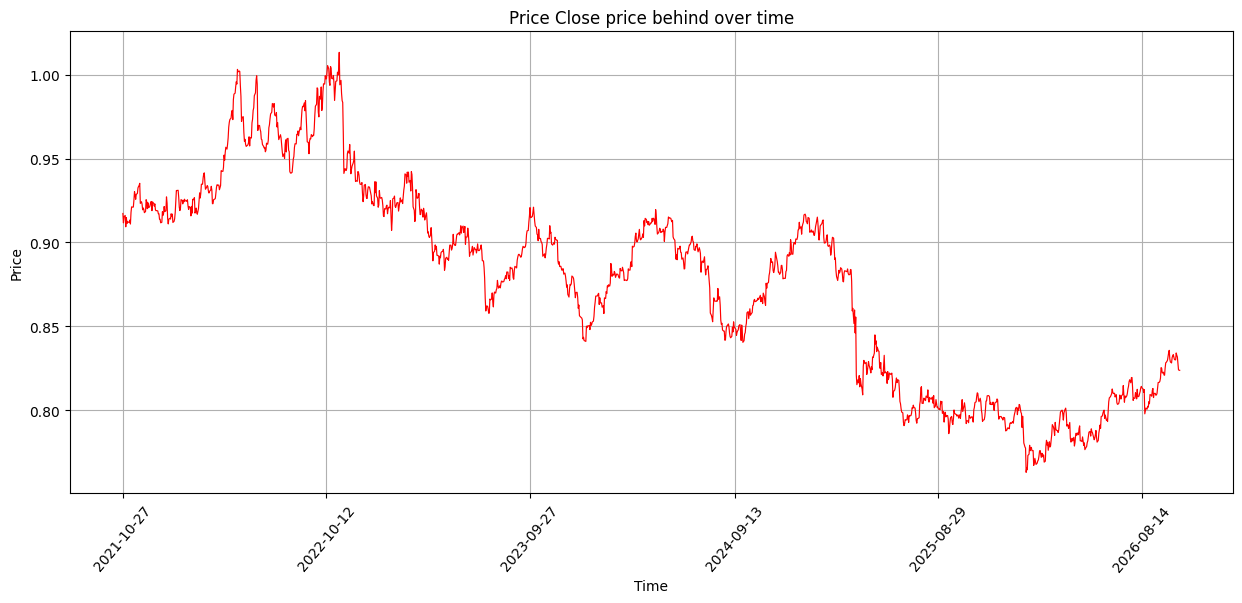

In [49]:
plot_lines_graph_forex(usdchf)

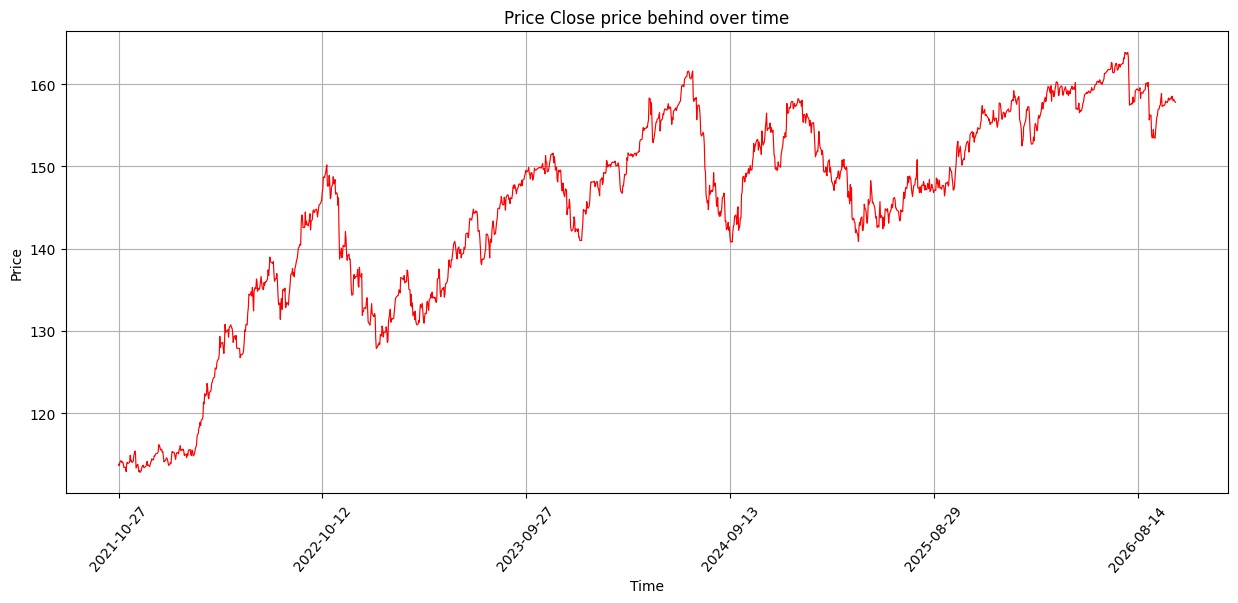

In [50]:
plot_lines_graph_forex(usdjpy)

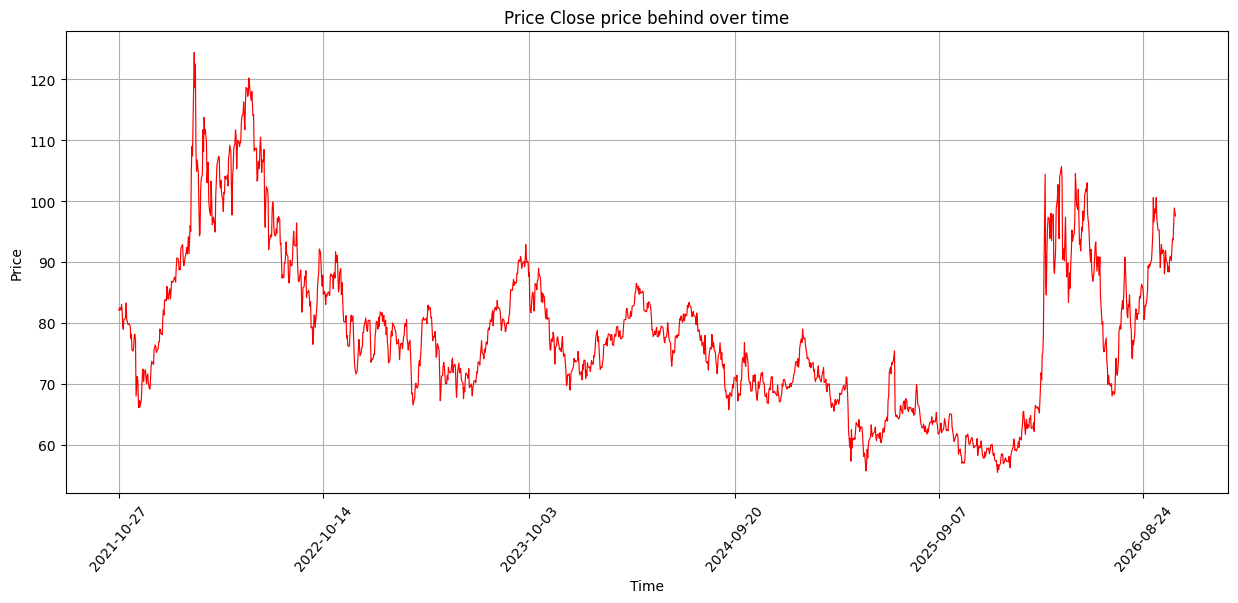

In [51]:
plot_lines_graph_forex(wti)

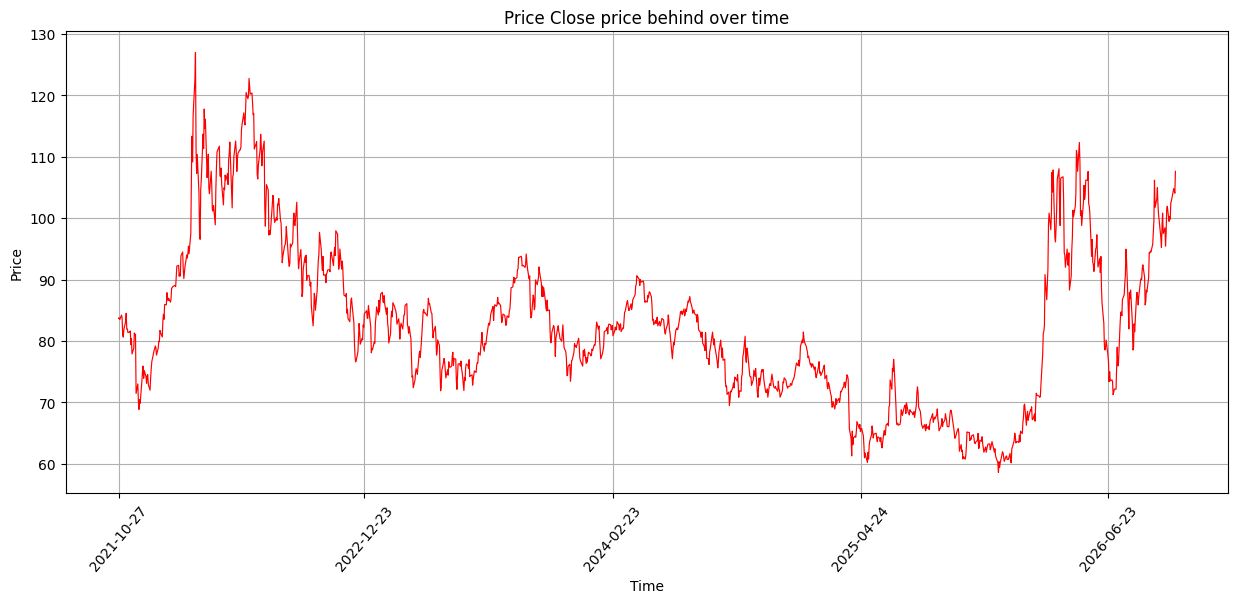

In [52]:
plot_lines_graph_forex(brent)

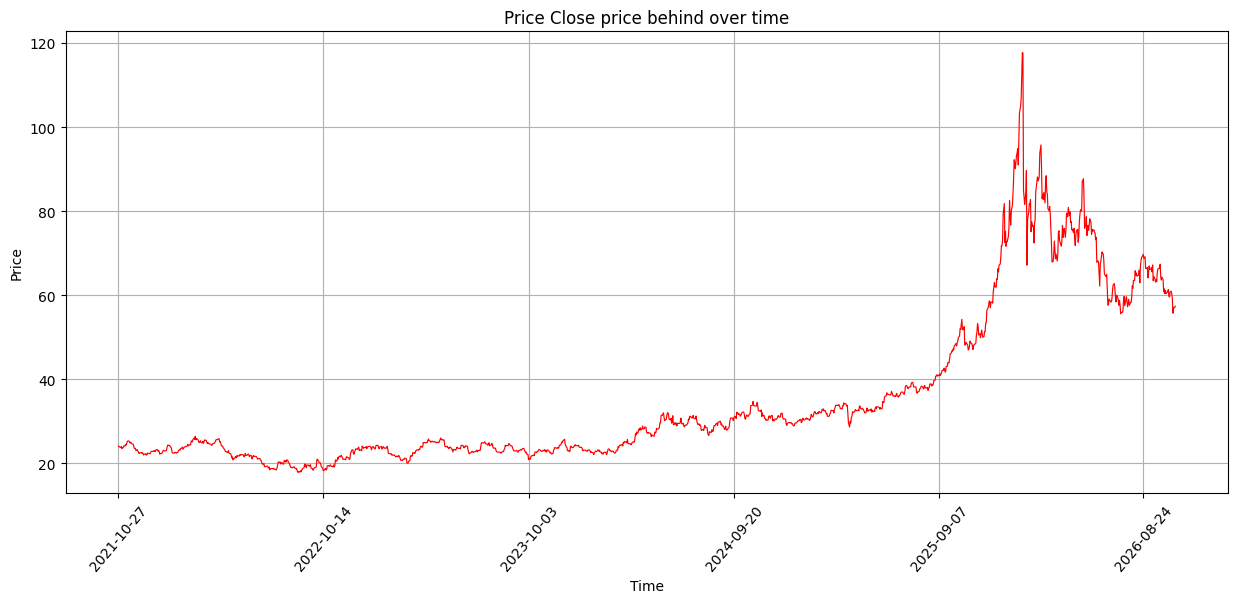

In [53]:
plot_lines_graph_forex(silver)

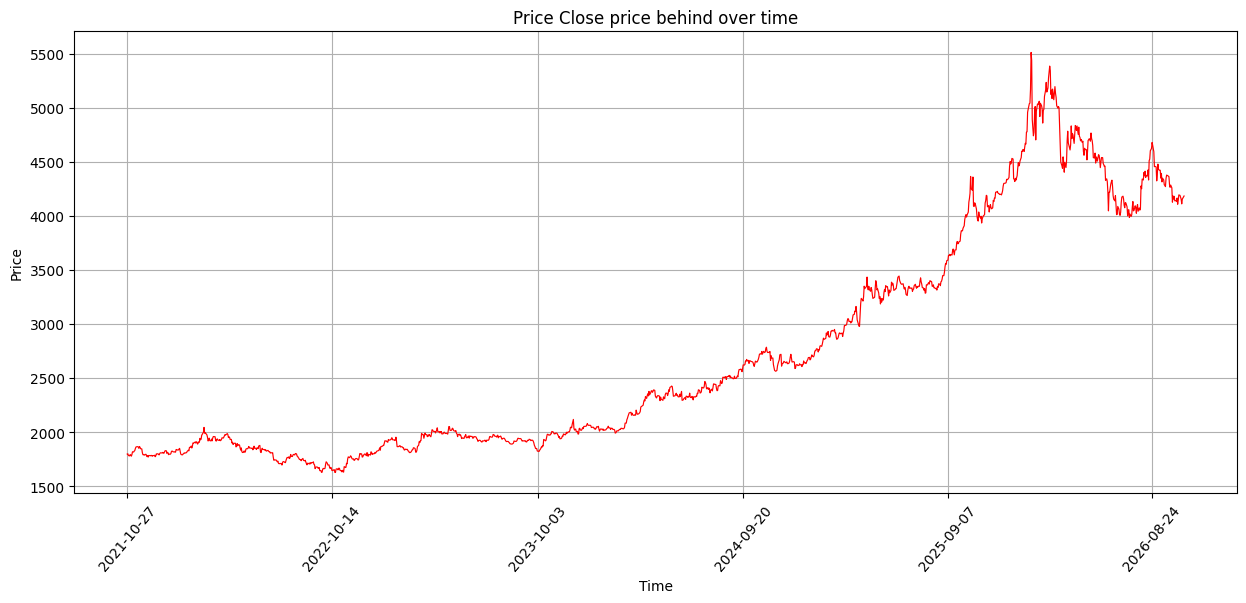

In [54]:
plot_lines_graph_forex(gold)

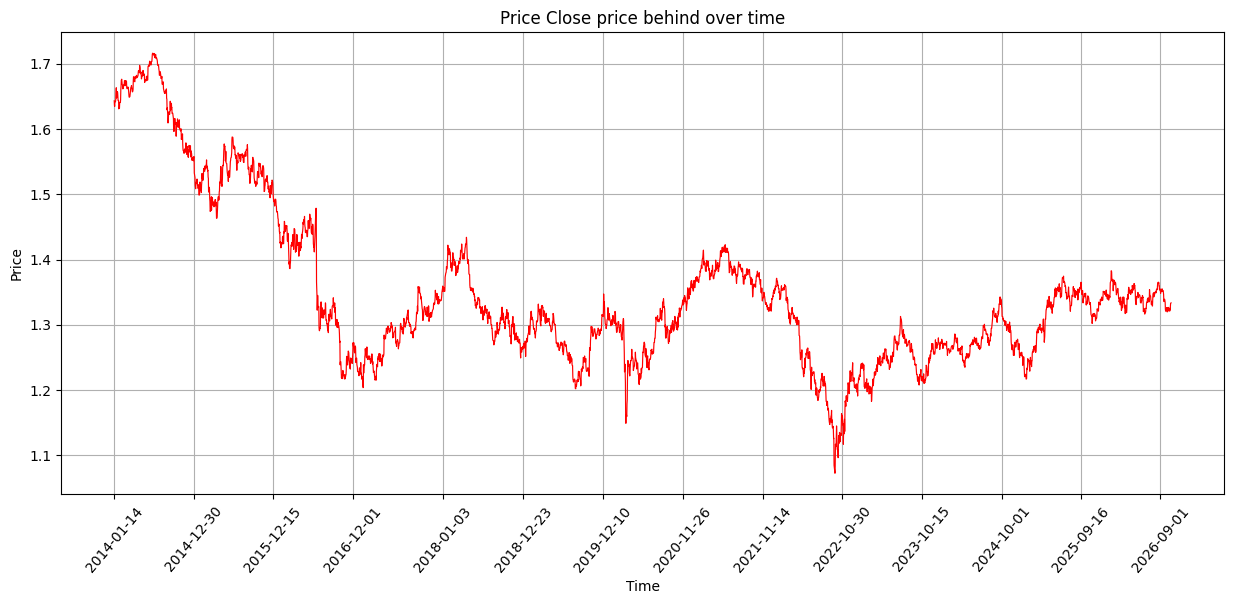

In [55]:
plot_lines_graph_forex(gbpusd)

In [56]:
def plot_lines_graph_macro(df):

    plt.plot(df.reference_date, df.inflation_yoy, linewidth=0.85, color='green', label='Inflation')
    plt.plot(df.reference_date, df.central_bank_rate, linewidth=0.85, color='blue', label='Interest')
    plt.plot(df.reference_date, df.real_gdp_growth_qoq, linewidth=0.85, color='red', label='PIB')
    plt.xlabel('Time')
    plt.ylabel('Value')
    ax = plt.gca()
    ax.set_xticks(df.reference_date[::50])
    plt.xticks(rotation=50)
    plt.title('Macro indicators values')
    plt.legend()
    plt.grid(True)
    plt.show()

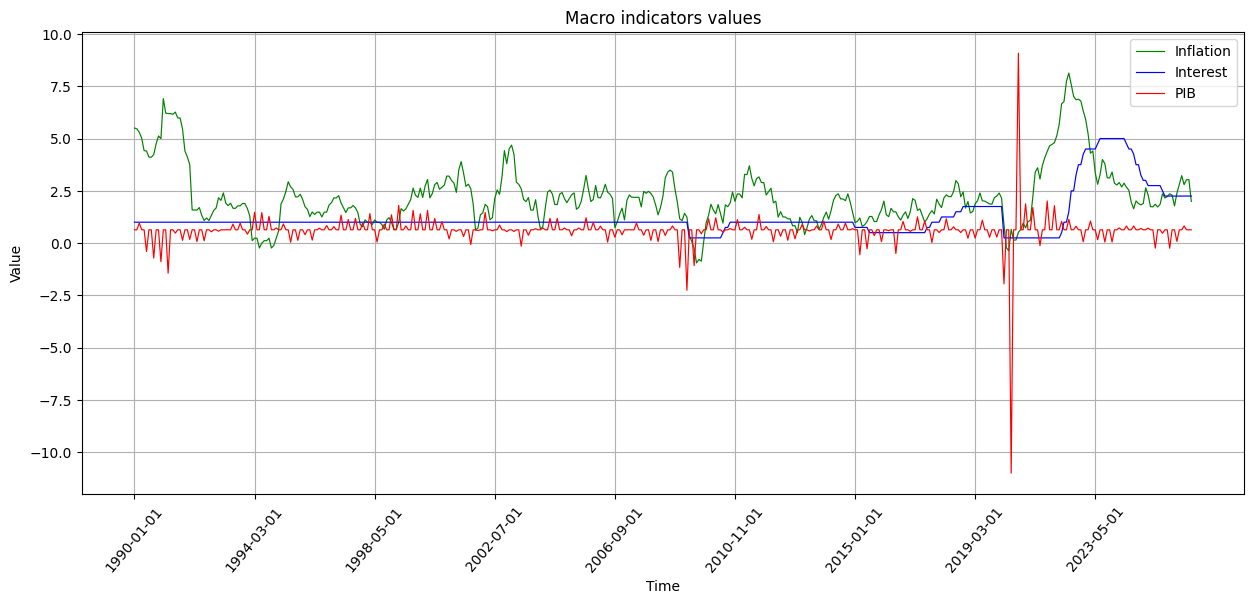

In [57]:
plot_lines_graph_macro(canada)

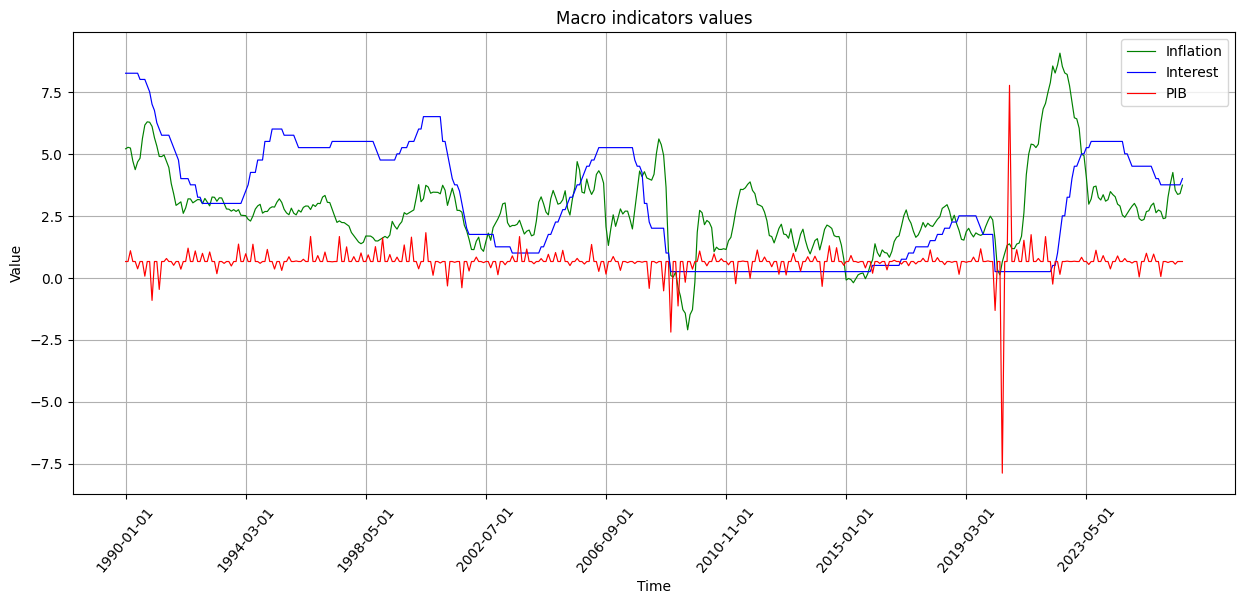

In [58]:
plot_lines_graph_macro(usa)

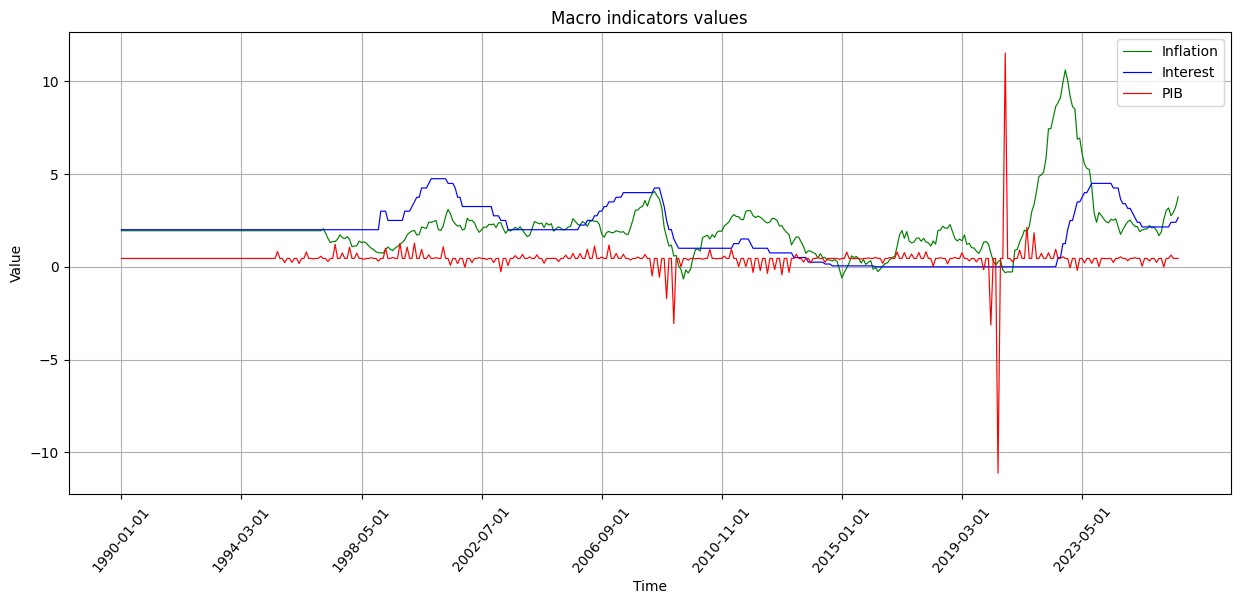

In [59]:
plot_lines_graph_macro(euro_zone)

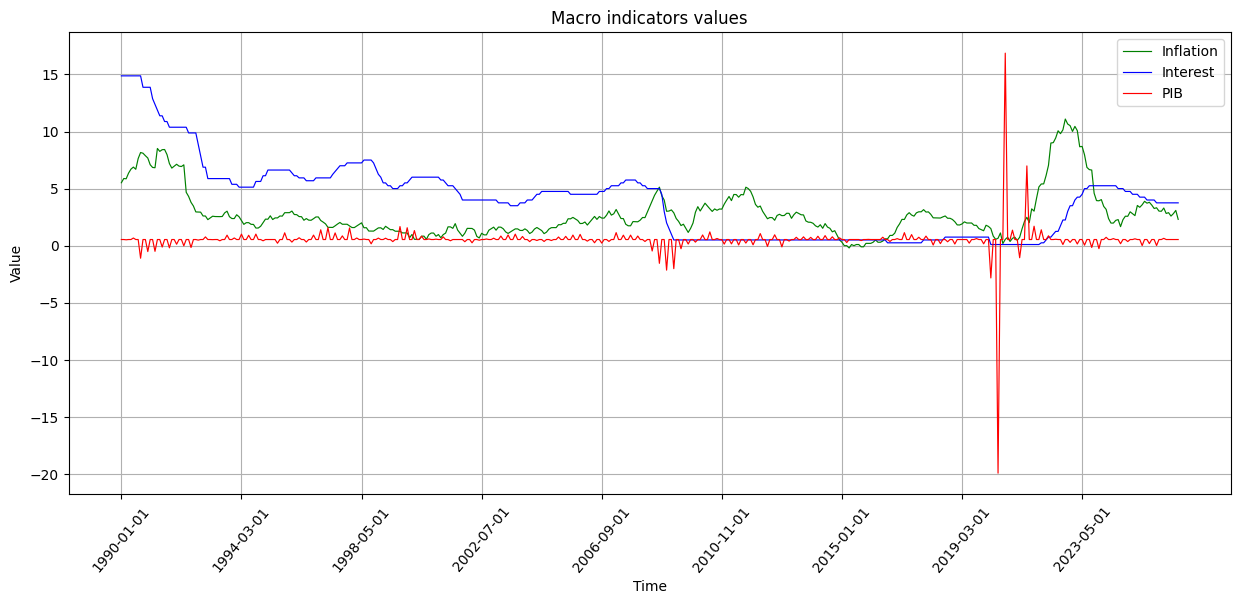

In [60]:
plot_lines_graph_macro(england)

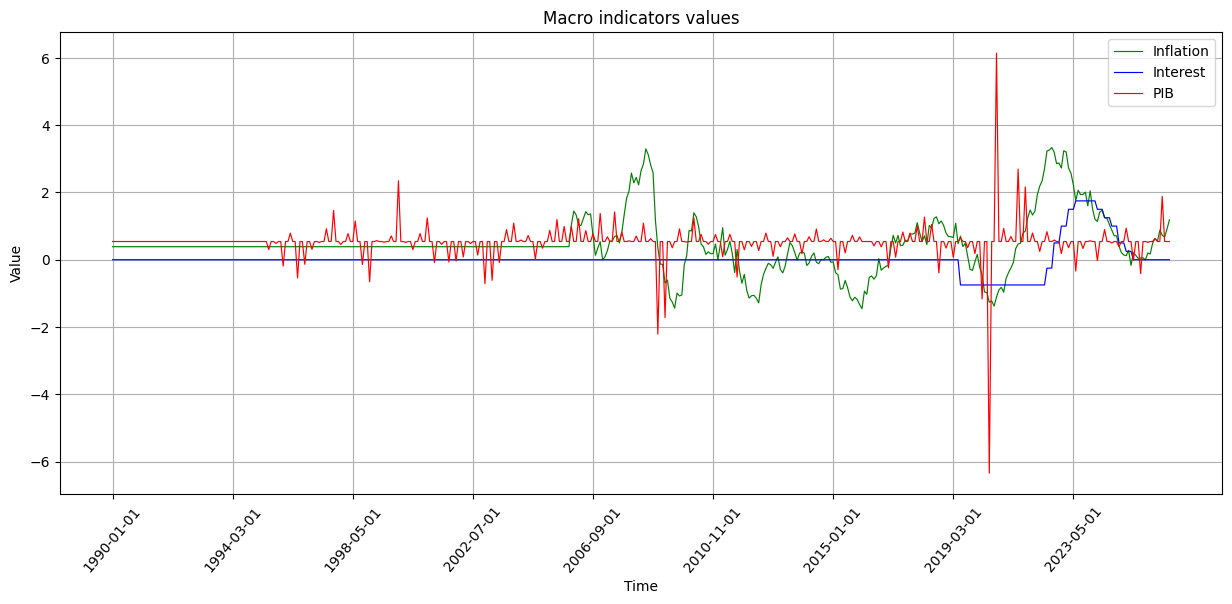

In [61]:
plot_lines_graph_macro(switz)

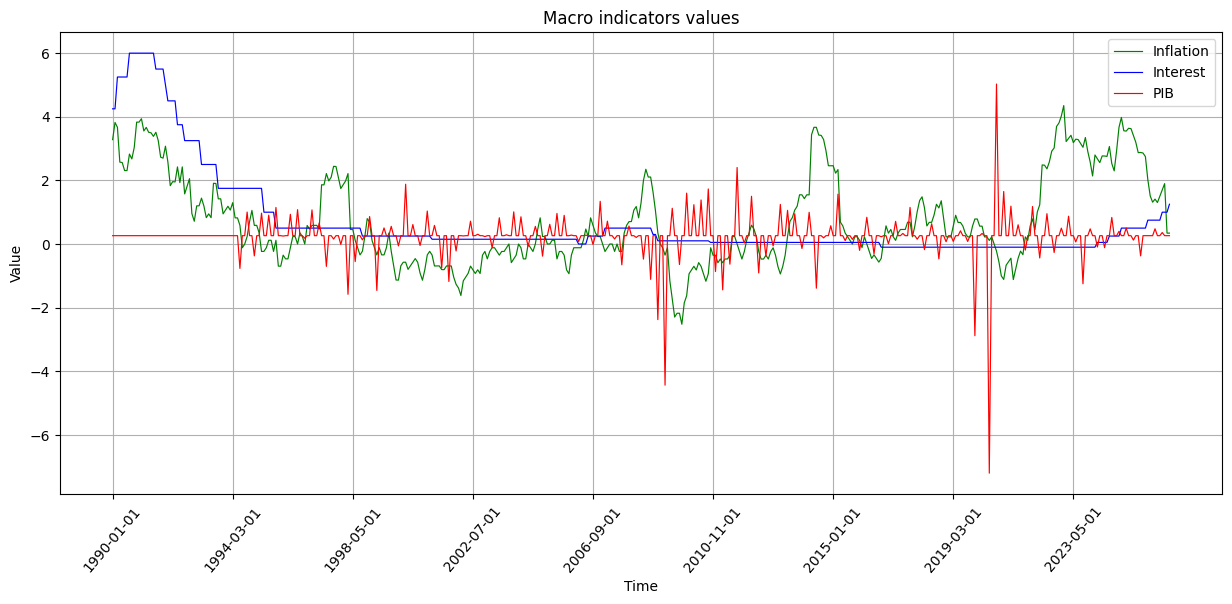

In [62]:
plot_lines_graph_macro(japan)

# Integrating macro data with their respective forex market counterparts

In [63]:
canada

,reference_date,inflation_yoy,central_bank_rate,real_gdp_growth_qoq
0,1990-01-01,5.502063,1.00,0.636564
1,1990-02-01,5.464481,1.00,0.636564
2,1990-03-01,5.298913,1.00,0.961690
3,1990-04-01,5.013550,1.00,0.636564
4,1990-05-01,4.423592,1.00,0.636564
...,...,...,...,...
436,2026-05-01,3.225806,2.25,0.636564
437,2026-06-01,2.798054,2.25,0.819738
438,2026-07-01,3.032141,2.25,0.636564
439,2026-08-01,3.033981,2.25,0.636564


In [64]:

def join_macro_forex_data(df_forex, **macro_dfs):
    df = df_forex.copy()

    df["time"] = pd.to_datetime(df["time"], utc=True)
    df = df.sort_values("time").drop_duplicates("time", keep="last")
    df["year_month"] = df["time"].dt.tz_localize(None).dt.to_period("M")

    for country, macro_df in macro_dfs.items():
        macro = macro_df.copy()

        macro["reference_date"] = pd.to_datetime(
            macro["reference_date"], utc=True
        ).dt.tz_localize(None)

        columns = [
            "inflation_yoy",
            "central_bank_rate",
            "real_gdp_growth_qoq"
        ]

        macro = macro.sort_values("reference_date")
        macro["year_month"] = macro["reference_date"].dt.to_period("M")
        macro = macro.drop_duplicates("year_month", keep="last")

        macro = macro[["year_month"] + columns].rename(
            columns={c: f"{country}_{c}" for c in columns}
        )

        df = df.merge(
            macro,
            on="year_month",
            how="left",
            validate="many_to_one"
        )

    df = df.sort_values("time").drop(columns="year_month")

    macro_columns = [
        c for c in df.columns
        if c.endswith((
            "inflation_yoy",
            "central_bank_rate",
            "real_gdp_growth_qoq"
        ))
    ]

    df[macro_columns] = df[macro_columns].ffill()

    # Mantém time como índice, como no seu DataFrame atual
    df = df.set_index("time")

    return df

In [65]:
eurcad_macro = join_macro_forex_data(eurcad, euro_zone=euro_zone, canada=canada )

In [66]:
eurcad_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_zone_inflation_yoy,euro_zone_central_bank_rate,euro_zone_real_gdp_growth_qoq,canada_inflation_yoy,canada_central_bank_rate,canada_real_gdp_growth_qoq
time,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.43125,1.43267,1.43125,1.43235,425,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-10-28 00:00:00+00:00,1.43339,1.44342,1.43088,1.44238,23728,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-10-29 00:00:00+00:00,1.44240,1.44415,1.42951,1.43132,30462,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-10-31 00:00:00+00:00,1.43096,1.43191,1.43069,1.43102,1187,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-11-01 00:00:00+00:00,1.43099,1.43616,1.42959,1.43527,22533,20,0,EURCADm,4.864865,0.00,0.45164,4.720407,0.25,0.636564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.59354,1.59619,1.58960,1.59241,19712,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564
2026-10-14 00:00:00+00:00,1.59238,1.59250,1.58612,1.59086,27806,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564
2026-10-15 00:00:00+00:00,1.59084,1.59608,1.58933,1.59141,33480,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564


In [67]:
usdcad_macro = join_macro_forex_data(usdcad, usa=usa, canada=canada )

In [68]:
usdcad_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,canada_inflation_yoy,canada_central_bank_rate,canada_real_gdp_growth_qoq
time,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.23239,1.23416,1.23239,1.23370,530,12,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564
2021-10-28 00:00:00+00:00,1.23681,1.23727,1.23293,1.23465,23003,12,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564
2021-10-29 00:00:00+00:00,1.23469,1.24075,1.23270,1.23798,33752,12,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564
2021-10-31 00:00:00+00:00,1.23795,1.23856,1.23759,1.23828,605,22,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564
2021-11-01 00:00:00+00:00,1.23833,1.24029,1.23510,1.23732,23179,12,0,USDCADm,6.809003,0.25,0.65756,4.720407,0.25,0.636564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.42799,1.42822,1.42030,1.42170,14001,14,0,USDCADm,3.737685,4.00,0.65756,1.992582,2.25,0.636564
2026-10-14 00:00:00+00:00,1.42167,1.42992,1.41964,1.42128,20085,14,0,USDCADm,3.737685,4.00,0.65756,1.992582,2.25,0.636564
2026-10-15 00:00:00+00:00,1.42125,1.42215,1.41689,1.41935,22131,14,0,USDCADm,3.737685,4.00,0.65756,1.992582,2.25,0.636564


In [69]:
eurchf_macro = join_macro_forex_data(eurchf, euro_zone=euro_zone, switz=switz)

In [70]:
eurchf_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_zone_inflation_yoy,euro_zone_central_bank_rate,euro_zone_real_gdp_growth_qoq,switz_inflation_yoy,switz_central_bank_rate,switz_real_gdp_growth_qoq
time,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.06492,1.06492,1.06476,1.06492,70,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029
2021-10-28 00:00:00+00:00,1.06443,1.06698,1.06350,1.06497,9207,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029
2021-10-29 00:00:00+00:00,1.06499,1.06542,1.05687,1.05812,10830,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029
2021-10-31 00:00:00+00:00,1.05726,1.05883,1.05722,1.05863,832,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029
2021-11-01 00:00:00+00:00,1.05864,1.06028,1.05339,1.05473,9813,29,0,EURCHFm,4.864865,0.00,0.45164,1.480210,-0.75,0.542029
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,0.93078,0.93270,0.93055,0.93270,8753,16,0,EURCHFm,3.770394,2.65,0.45164,1.187862,0.00,0.542029
2026-10-14 00:00:00+00:00,0.93268,0.93341,0.93039,0.93103,13154,16,0,EURCHFm,3.770394,2.65,0.45164,1.187862,0.00,0.542029
2026-10-15 00:00:00+00:00,0.93105,0.93145,0.92692,0.92809,17408,16,0,EURCHFm,3.770394,2.65,0.45164,1.187862,0.00,0.542029


In [71]:
eurgbp_macro = join_macro_forex_data(eurgbp, euro=euro_zone, gbp=england)

In [72]:
eurjpy_macro = join_macro_forex_data(eurjpy, euro=euro_zone, japan=japan)

In [73]:
eurusd_macro = join_macro_forex_data(eurusd, euro=euro_zone, usa=usa)

In [74]:
usdchf_macro = join_macro_forex_data(usdchf, usa=usa, switz=switz)
usdjpy_macro = join_macro_forex_data(usdjpy, usa=usa, japan=japan)
gbpusd_macro = join_macro_forex_data(gbpusd, gbp=england, usa=usa)

In [75]:
usdchf_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,switz_inflation_yoy,switz_central_bank_rate,switz_real_gdp_growth_qoq
time,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,0.91702,0.91739,0.91699,0.91728,239,10,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029
2021-10-28 00:00:00+00:00,0.91857,0.91942,0.91119,0.91168,22939,10,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029
2021-10-29 00:00:00+00:00,0.91169,0.91757,0.91018,0.91532,26238,10,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029
2021-10-31 00:00:00+00:00,0.91541,0.91628,0.91528,0.91612,454,15,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029
2021-11-01 00:00:00+00:00,0.91614,0.91710,0.90841,0.90933,20001,10,0,USDCHFm,6.809003,0.25,0.65756,1.480210,-0.75,0.542029
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,0.83405,0.83445,0.83128,0.83269,13549,13,0,USDCHFm,3.737685,4.00,0.65756,1.187862,0.00,0.542029
2026-10-14 00:00:00+00:00,0.83267,0.83943,0.83156,0.83169,20693,13,0,USDCHFm,3.737685,4.00,0.65756,1.187862,0.00,0.542029
2026-10-15 00:00:00+00:00,0.83167,0.83238,0.82642,0.82774,32046,13,0,USDCHFm,3.737685,4.00,0.65756,1.187862,0.00,0.542029


eurcad_macro

eurchf_macro

eurgbp_macro

eurjpy_macro

eurusd_macro

usdcad_macro

usdchf_macro

usdjpy_macro

gbpusd_macro

In [76]:
eurcad_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_zone_inflation_yoy,euro_zone_central_bank_rate,euro_zone_real_gdp_growth_qoq,canada_inflation_yoy,canada_central_bank_rate,canada_real_gdp_growth_qoq
time,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.43125,1.43267,1.43125,1.43235,425,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-10-28 00:00:00+00:00,1.43339,1.44342,1.43088,1.44238,23728,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-10-29 00:00:00+00:00,1.44240,1.44415,1.42951,1.43132,30462,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-10-31 00:00:00+00:00,1.43096,1.43191,1.43069,1.43102,1187,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564
2021-11-01 00:00:00+00:00,1.43099,1.43616,1.42959,1.43527,22533,20,0,EURCADm,4.864865,0.00,0.45164,4.720407,0.25,0.636564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.59354,1.59619,1.58960,1.59241,19712,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564
2026-10-14 00:00:00+00:00,1.59238,1.59250,1.58612,1.59086,27806,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564
2026-10-15 00:00:00+00:00,1.59084,1.59608,1.58933,1.59141,33480,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564


In [77]:
eurcad_macro['difference_inflation'] = eurcad_macro.euro_zone_inflation_yoy - eurcad_macro.canada_inflation_yoy
eurcad_macro['difference_interest'] = eurcad_macro.euro_zone_central_bank_rate - eurcad_macro.canada_central_bank_rate
eurcad_macro['difference_pib'] = eurcad_macro.euro_zone_real_gdp_growth_qoq - eurcad_macro.canada_real_gdp_growth_qoq

In [78]:
eurchf_macro['difference_inflation'] = eurchf_macro.euro_zone_inflation_yoy - eurchf_macro.switz_inflation_yoy
eurchf_macro['difference_interest'] = eurchf_macro.euro_zone_central_bank_rate - eurchf_macro.switz_central_bank_rate
eurchf_macro['difference_pib'] = eurchf_macro.euro_zone_real_gdp_growth_qoq - eurchf_macro.switz_real_gdp_growth_qoq

In [79]:
eurgbp_macro['difference_inflation'] = eurgbp_macro.euro_inflation_yoy - eurgbp_macro.gbp_inflation_yoy
eurgbp_macro['difference_interest'] = eurgbp_macro.euro_central_bank_rate - eurgbp_macro.gbp_central_bank_rate
eurgbp_macro['difference_pib'] = eurgbp_macro.euro_real_gdp_growth_qoq - eurgbp_macro.gbp_real_gdp_growth_qoq

In [80]:
eurjpy_macro['difference_inflation'] = eurjpy_macro.euro_inflation_yoy - eurjpy_macro.japan_inflation_yoy
eurjpy_macro['difference_interest'] = eurjpy_macro.euro_central_bank_rate - eurjpy_macro.japan_central_bank_rate
eurjpy_macro['difference_pib'] = eurjpy_macro.euro_real_gdp_growth_qoq - eurjpy_macro.japan_real_gdp_growth_qoq

In [81]:
eurusd_macro['difference_inflation'] = eurusd_macro.euro_inflation_yoy - eurusd_macro.usa_inflation_yoy
eurusd_macro['difference_interest'] = eurusd_macro.euro_central_bank_rate - eurusd_macro.usa_central_bank_rate
eurusd_macro['difference_pib'] = eurusd_macro.euro_real_gdp_growth_qoq - eurusd_macro.usa_real_gdp_growth_qoq

In [82]:
usdcad_macro['difference_inflation'] = usdcad_macro.usa_inflation_yoy - usdcad_macro.canada_inflation_yoy
usdcad_macro['difference_interest'] = usdcad_macro.usa_central_bank_rate - usdcad_macro.canada_central_bank_rate
usdcad_macro['differene_pib'] = usdcad_macro.usa_real_gdp_growth_qoq - usdcad_macro.canada_real_gdp_growth_qoq

In [83]:
usdchf_macro['difference_inflation'] = usdchf_macro.usa_inflation_yoy - usdchf_macro.switz_inflation_yoy
usdchf_macro['difference_interest'] = usdchf_macro.usa_central_bank_rate - usdchf_macro.switz_central_bank_rate
usdchf_macro['difference_pib'] = usdchf_macro.usa_real_gdp_growth_qoq - usdchf_macro.switz_real_gdp_growth_qoq

In [84]:
usdjpy_macro['difference_inflation'] = usdjpy_macro.usa_inflation_yoy - usdjpy_macro.japan_inflation_yoy
usdjpy_macro['difference_interest'] = usdjpy_macro.usa_central_bank_rate - usdjpy_macro.japan_central_bank_rate
usdjpy_macro['difference_pib'] = usdjpy_macro.usa_real_gdp_growth_qoq - usdjpy_macro.japan_real_gdp_growth_qoq

In [85]:
gbpusd_macro['difference_inflation'] = gbpusd_macro.gbp_inflation_yoy - gbpusd_macro.usa_inflation_yoy
gbpusd_macro['difference_interest'] = gbpusd_macro.gbp_central_bank_rate - gbpusd_macro.usa_central_bank_rate
gbpusd_macro['difference_pib'] = gbpusd_macro.gbp_real_gdp_growth_qoq - gbpusd_macro.usa_real_gdp_growth_qoq

In [86]:
eurcad_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_zone_inflation_yoy,euro_zone_central_bank_rate,euro_zone_real_gdp_growth_qoq,canada_inflation_yoy,canada_central_bank_rate,canada_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.43125,1.43267,1.43125,1.43235,425,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564,-0.601650,-0.25,-0.184923
2021-10-28 00:00:00+00:00,1.43339,1.44342,1.43088,1.44238,23728,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564,-0.601650,-0.25,-0.184923
2021-10-29 00:00:00+00:00,1.44240,1.44415,1.42951,1.43132,30462,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564,-0.601650,-0.25,-0.184923
2021-10-31 00:00:00+00:00,1.43096,1.43191,1.43069,1.43102,1187,20,0,EURCADm,4.052896,0.00,0.45164,4.654545,0.25,0.636564,-0.601650,-0.25,-0.184923
2021-11-01 00:00:00+00:00,1.43099,1.43616,1.42959,1.43527,22533,20,0,EURCADm,4.864865,0.00,0.45164,4.720407,0.25,0.636564,0.144458,-0.25,-0.184923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.59354,1.59619,1.58960,1.59241,19712,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564,1.777812,0.40,-0.184923
2026-10-14 00:00:00+00:00,1.59238,1.59250,1.58612,1.59086,27806,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564,1.777812,0.40,-0.184923
2026-10-15 00:00:00+00:00,1.59084,1.59608,1.58933,1.59141,33480,15,0,EURCADm,3.770394,2.65,0.45164,1.992582,2.25,0.636564,1.777812,0.40,-0.184923


In [87]:
eurchf_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_zone_inflation_yoy,euro_zone_central_bank_rate,euro_zone_real_gdp_growth_qoq,switz_inflation_yoy,switz_central_bank_rate,switz_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.06492,1.06492,1.06476,1.06492,70,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029,2.802495,0.75,-0.090389
2021-10-28 00:00:00+00:00,1.06443,1.06698,1.06350,1.06497,9207,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029,2.802495,0.75,-0.090389
2021-10-29 00:00:00+00:00,1.06499,1.06542,1.05687,1.05812,10830,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029,2.802495,0.75,-0.090389
2021-10-31 00:00:00+00:00,1.05726,1.05883,1.05722,1.05863,832,29,0,EURCHFm,4.052896,0.00,0.45164,1.250401,-0.75,0.542029,2.802495,0.75,-0.090389
2021-11-01 00:00:00+00:00,1.05864,1.06028,1.05339,1.05473,9813,29,0,EURCHFm,4.864865,0.00,0.45164,1.480210,-0.75,0.542029,3.384655,0.75,-0.090389
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,0.93078,0.93270,0.93055,0.93270,8753,16,0,EURCHFm,3.770394,2.65,0.45164,1.187862,0.00,0.542029,2.582532,2.65,-0.090389
2026-10-14 00:00:00+00:00,0.93268,0.93341,0.93039,0.93103,13154,16,0,EURCHFm,3.770394,2.65,0.45164,1.187862,0.00,0.542029,2.582532,2.65,-0.090389
2026-10-15 00:00:00+00:00,0.93105,0.93145,0.92692,0.92809,17408,16,0,EURCHFm,3.770394,2.65,0.45164,1.187862,0.00,0.542029,2.582532,2.65,-0.090389


In [88]:
eurgbp_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_inflation_yoy,euro_central_bank_rate,euro_real_gdp_growth_qoq,gbp_inflation_yoy,gbp_central_bank_rate,gbp_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,0.84414,0.84421,0.84406,0.84414,115,16,0,EURGBPm,4.052896,0.00,0.45164,4.124656,0.10,0.537796,-0.071760,-0.1,-0.086156
2021-10-28 00:00:00+00:00,0.84274,0.84751,0.84221,0.84656,10785,16,0,EURGBPm,4.052896,0.00,0.45164,4.124656,0.10,0.537796,-0.071760,-0.1,-0.086156
2021-10-29 00:00:00+00:00,0.84657,0.84720,0.84325,0.84428,14942,16,0,EURGBPm,4.052896,0.00,0.45164,4.124656,0.10,0.537796,-0.071760,-0.1,-0.086156
2021-10-31 00:00:00+00:00,0.84431,0.84483,0.84416,0.84452,635,16,0,EURGBPm,4.052896,0.00,0.45164,4.124656,0.10,0.537796,-0.071760,-0.1,-0.086156
2021-11-01 00:00:00+00:00,0.84454,0.84987,0.84417,0.84940,12577,16,0,EURGBPm,4.864865,0.00,0.45164,5.142332,0.10,0.537796,-0.277468,-0.1,-0.086156
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,0.84476,0.84572,0.84431,0.84485,5924,13,0,EURGBPm,3.770394,2.65,0.45164,2.304673,3.75,0.537796,1.465721,-1.1,-0.086156
2026-10-14 00:00:00+00:00,0.84484,0.84622,0.84262,0.84610,9601,13,0,EURGBPm,3.770394,2.65,0.45164,2.304673,3.75,0.537796,1.465721,-1.1,-0.086156
2026-10-15 00:00:00+00:00,0.84608,0.84771,0.84455,0.84485,11127,13,0,EURGBPm,3.770394,2.65,0.45164,2.304673,3.75,0.537796,1.465721,-1.1,-0.086156


In [89]:
eurjpy_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_inflation_yoy,euro_central_bank_rate,euro_real_gdp_growth_qoq,japan_inflation_yoy,japan_central_bank_rate,japan_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,132.056,132.084,132.018,132.084,237,19,0,EURJPYm,4.052896,0.00,0.45164,0.112107,-0.10,0.261897,3.940788,0.1,0.189743
2021-10-28 00:00:00+00:00,131.692,132.726,131.549,132.721,20494,19,0,EURJPYm,4.052896,0.00,0.45164,0.112107,-0.10,0.261897,3.940788,0.1,0.189743
2021-10-29 00:00:00+00:00,132.723,132.909,131.599,131.808,28448,19,0,EURJPYm,4.052896,0.00,0.45164,0.112107,-0.10,0.261897,3.940788,0.1,0.189743
2021-10-31 00:00:00+00:00,131.801,132.047,131.797,132.009,1575,19,0,EURJPYm,4.052896,0.00,0.45164,0.112107,-0.10,0.261897,3.940788,0.1,0.189743
2021-11-01 00:00:00+00:00,132.011,132.436,131.788,132.336,23391,19,0,EURJPYm,4.864865,0.00,0.45164,0.562430,-0.10,0.261897,4.302435,0.1,0.189743
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,176.907,177.374,176.477,177.335,33980,16,0,EURJPYm,3.770394,2.65,0.45164,0.342075,1.25,0.261897,3.428319,1.4,0.189743
2026-10-14 00:00:00+00:00,177.331,177.586,176.285,176.846,40469,16,0,EURJPYm,3.770394,2.65,0.45164,0.342075,1.25,0.261897,3.428319,1.4,0.189743
2026-10-15 00:00:00+00:00,176.843,177.411,176.634,177.305,50785,16,0,EURJPYm,3.770394,2.65,0.45164,0.342075,1.25,0.261897,3.428319,1.4,0.189743


In [90]:
eurusd_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_inflation_yoy,euro_central_bank_rate,euro_real_gdp_growth_qoq,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2014-01-14 00:00:00+00:00,1.36669,1.36983,1.36485,1.36661,58248,0,0,EURUSDm,0.761355,0.25,0.45164,1.578947,0.25,0.65756,-0.817593,0.00,-0.20592
2014-01-15 00:00:00+00:00,1.36665,1.36723,1.35807,1.35986,60319,0,0,EURUSDm,0.761355,0.25,0.45164,1.578947,0.25,0.65756,-0.817593,0.00,-0.20592
2014-01-16 00:00:00+00:00,1.35990,1.36487,1.35827,1.36145,72629,0,0,EURUSDm,0.761355,0.25,0.45164,1.578947,0.25,0.65756,-0.817593,0.00,-0.20592
2014-01-17 00:00:00+00:00,1.36129,1.36205,1.35166,1.35382,64588,0,0,EURUSDm,0.761355,0.25,0.45164,1.578947,0.25,0.65756,-0.817593,0.00,-0.20592
2014-01-19 00:00:00+00:00,1.35365,1.35396,1.35238,1.35264,1682,0,0,EURUSDm,0.761355,0.25,0.45164,1.578947,0.25,0.65756,-0.817593,0.00,-0.20592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm,3.770394,2.65,0.45164,3.737685,4.00,0.65756,0.032709,-1.35,-0.20592
2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm,3.770394,2.65,0.45164,3.737685,4.00,0.65756,0.032709,-1.35,-0.20592
2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm,3.770394,2.65,0.45164,3.737685,4.00,0.65756,0.032709,-1.35,-0.20592


In [91]:
usdcad_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,canada_inflation_yoy,canada_central_bank_rate,canada_real_gdp_growth_qoq,difference_inflation,difference_interest,differene_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,1.23239,1.23416,1.23239,1.23370,530,12,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564,1.567323,0.00,0.020997
2021-10-28 00:00:00+00:00,1.23681,1.23727,1.23293,1.23465,23003,12,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564,1.567323,0.00,0.020997
2021-10-29 00:00:00+00:00,1.23469,1.24075,1.23270,1.23798,33752,12,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564,1.567323,0.00,0.020997
2021-10-31 00:00:00+00:00,1.23795,1.23856,1.23759,1.23828,605,22,0,USDCADm,6.221869,0.25,0.65756,4.654545,0.25,0.636564,1.567323,0.00,0.020997
2021-11-01 00:00:00+00:00,1.23833,1.24029,1.23510,1.23732,23179,12,0,USDCADm,6.809003,0.25,0.65756,4.720407,0.25,0.636564,2.088596,0.00,0.020997
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.42799,1.42822,1.42030,1.42170,14001,14,0,USDCADm,3.737685,4.00,0.65756,1.992582,2.25,0.636564,1.745103,1.75,0.020997
2026-10-14 00:00:00+00:00,1.42167,1.42992,1.41964,1.42128,20085,14,0,USDCADm,3.737685,4.00,0.65756,1.992582,2.25,0.636564,1.745103,1.75,0.020997
2026-10-15 00:00:00+00:00,1.42125,1.42215,1.41689,1.41935,22131,14,0,USDCADm,3.737685,4.00,0.65756,1.992582,2.25,0.636564,1.745103,1.75,0.020997


In [92]:
usdchf_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,switz_inflation_yoy,switz_central_bank_rate,switz_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,0.91702,0.91739,0.91699,0.91728,239,10,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029,4.971468,1.0,0.115531
2021-10-28 00:00:00+00:00,0.91857,0.91942,0.91119,0.91168,22939,10,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029,4.971468,1.0,0.115531
2021-10-29 00:00:00+00:00,0.91169,0.91757,0.91018,0.91532,26238,10,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029,4.971468,1.0,0.115531
2021-10-31 00:00:00+00:00,0.91541,0.91628,0.91528,0.91612,454,15,0,USDCHFm,6.221869,0.25,0.65756,1.250401,-0.75,0.542029,4.971468,1.0,0.115531
2021-11-01 00:00:00+00:00,0.91614,0.91710,0.90841,0.90933,20001,10,0,USDCHFm,6.809003,0.25,0.65756,1.480210,-0.75,0.542029,5.328793,1.0,0.115531
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,0.83405,0.83445,0.83128,0.83269,13549,13,0,USDCHFm,3.737685,4.00,0.65756,1.187862,0.00,0.542029,2.549823,4.0,0.115531
2026-10-14 00:00:00+00:00,0.83267,0.83943,0.83156,0.83169,20693,13,0,USDCHFm,3.737685,4.00,0.65756,1.187862,0.00,0.542029,2.549823,4.0,0.115531
2026-10-15 00:00:00+00:00,0.83167,0.83238,0.82642,0.82774,32046,13,0,USDCHFm,3.737685,4.00,0.65756,1.187862,0.00,0.542029,2.549823,4.0,0.115531


In [93]:
usdjpy_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,japan_inflation_yoy,japan_central_bank_rate,japan_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2021-10-27 00:00:00+00:00,113.710,113.769,113.697,113.767,326,8,0,USDJPYm,6.221869,0.25,0.65756,0.112107,-0.10,0.261897,6.109761,0.35,0.395663
2021-10-28 00:00:00+00:00,113.638,113.717,113.251,113.611,22194,8,0,USDJPYm,6.221869,0.25,0.65756,0.112107,-0.10,0.261897,6.109761,0.35,0.395663
2021-10-29 00:00:00+00:00,113.613,114.092,113.389,113.978,32390,8,0,USDJPYm,6.221869,0.25,0.65756,0.112107,-0.10,0.261897,6.109761,0.35,0.395663
2021-10-31 00:00:00+00:00,114.015,114.250,114.003,114.232,1135,11,0,USDJPYm,6.221869,0.25,0.65756,0.112107,-0.10,0.261897,6.109761,0.35,0.395663
2021-11-01 00:00:00+00:00,114.235,114.440,113.911,114.088,26075,8,0,USDJPYm,6.809003,0.25,0.65756,0.562430,-0.10,0.261897,6.246573,0.35,0.395663
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,158.526,158.527,157.827,158.316,44759,10,0,USDJPYm,3.737685,4.00,0.65756,0.342075,1.25,0.261897,3.395610,2.75,0.395663
2026-10-14 00:00:00+00:00,158.314,158.946,157.876,157.977,50733,10,0,USDJPYm,3.737685,4.00,0.65756,0.342075,1.25,0.261897,3.395610,2.75,0.395663
2026-10-15 00:00:00+00:00,157.975,158.242,157.543,158.135,72505,10,0,USDJPYm,3.737685,4.00,0.65756,0.342075,1.25,0.261897,3.395610,2.75,0.395663


In [94]:
gbpusd_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,gbp_inflation_yoy,gbp_central_bank_rate,gbp_real_gdp_growth_qoq,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib
time,,,,,,,,,,,,,,,,,
2014-01-14 00:00:00+00:00,1.63878,1.64633,1.63669,1.64318,53646,0,0,GBPUSDm,1.956746,0.50,0.537796,1.578947,0.25,0.65756,0.377798,0.25,-0.119765
2014-01-15 00:00:00+00:00,1.64325,1.64369,1.63222,1.63601,63863,0,0,GBPUSDm,1.956746,0.50,0.537796,1.578947,0.25,0.65756,0.377798,0.25,-0.119765
2014-01-16 00:00:00+00:00,1.63612,1.63815,1.63124,1.63458,57297,0,0,GBPUSDm,1.956746,0.50,0.537796,1.578947,0.25,0.65756,0.377798,0.25,-0.119765
2014-01-17 00:00:00+00:00,1.63445,1.64576,1.63088,1.64170,57879,0,0,GBPUSDm,1.956746,0.50,0.537796,1.578947,0.25,0.65756,0.377798,0.25,-0.119765
2014-01-19 00:00:00+00:00,1.64167,1.64197,1.64091,1.64165,1954,0,0,GBPUSDm,1.956746,0.50,0.537796,1.578947,0.25,0.65756,0.377798,0.25,-0.119765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.32092,1.32588,1.32039,1.32568,32676,7,0,GBPUSDm,2.304673,3.75,0.537796,3.737685,4.00,0.65756,-1.433011,-0.25,-0.119765
2026-10-14 00:00:00+00:00,1.32565,1.32751,1.31364,1.32289,51418,4,0,GBPUSDm,2.304673,3.75,0.537796,3.737685,4.00,0.65756,-1.433011,-0.25,-0.119765
2026-10-15 00:00:00+00:00,1.32287,1.32780,1.32208,1.32700,58362,7,0,GBPUSDm,2.304673,3.75,0.537796,3.737685,4.00,0.65756,-1.433011,-0.25,-0.119765


In [95]:
import ta

In [96]:
# Create a variation of data

def create_variation(df):

    # Import libraries
    from ta.trend import EMAIndicator, ADXIndicator
    from ta.volatility import AverageTrueRange

    # Copy df
    df = df.copy()

    # Create daily return
    df['daily_return'] = df['close'].pct_change() * 100

    # Create daily range
    df['daily_range'] = df['high'] - df['low']

    # Calculate standard deviation of the last 5 days
    df['daily_volatility'] = (
        df['close'].pct_change().rolling(window=5).std() * 100
    )

    # Create EMA 21
    df['ema21'] = EMAIndicator(
        close=df['close'], window=21, fillna=False
    ).ema_indicator()

    # Create EMA 55
    df['ema55'] = EMAIndicator(
        close=df['close'], window=55, fillna=False
    ).ema_indicator()

    # Create ADX 14
    df['adx14'] = ADXIndicator(
        high=df['high'],
        low=df['low'],
        close=df['close'],
        window=14,
        fillna=False
    ).adx()

    # Create ATR 14
    df['atr14'] = AverageTrueRange(
        high=df['high'],
        low=df['low'],
        close=df['close'],
        window=14,
        fillna=False
    ).average_true_range()

    # Drop NaN values
    df = df.dropna()

    # Return df
    return df

In [97]:
eurcad_macro = create_variation(eurusd_macro)

In [98]:
eurcad_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_inflation_yoy,euro_central_bank_rate,...,difference_inflation,difference_interest,difference_pib,daily_return,daily_range,daily_volatility,ema21,ema55,adx14,atr14
time,,,,,,,,,,,,,,,,,,,,,
2014-03-18 00:00:00+00:00,1.39247,1.39420,1.38792,1.39281,57639,0,0,EURUSDm,0.465357,0.25,...,-1.046846,0.00,0.841412,0.028009,0.00628,0.206857,1.383010,1.374533,32.126269,0.006486
2014-03-19 00:00:00+00:00,1.39287,1.39317,1.38093,1.38172,66539,0,0,EURUSDm,0.465357,0.25,...,-1.046846,0.00,0.841412,-0.796232,0.01224,0.423795,1.382893,1.374790,31.603522,0.006897
2014-03-20 00:00:00+00:00,1.38183,1.38443,1.37486,1.37776,67888,0,0,EURUSDm,0.465357,0.25,...,-1.046846,0.00,0.841412,-0.286599,0.00957,0.373716,1.382426,1.374896,29.880062,0.007088
2014-03-21 00:00:00+00:00,1.37784,1.38101,1.37651,1.37871,44134,0,0,EURUSDm,0.465357,0.25,...,-1.046846,0.00,0.841412,0.068953,0.00450,0.381984,1.382088,1.375032,28.279707,0.006903
2014-03-23 00:00:00+00:00,1.37969,1.38051,1.37870,1.37960,2116,0,0,EURUSDm,0.465357,0.25,...,-1.046846,0.00,0.841412,0.064553,0.00181,0.372849,1.381862,1.375195,26.793663,0.006539
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm,3.770394,2.65,...,0.032709,-1.35,-0.205920,0.371887,0.00508,0.283405,1.129616,1.141179,56.304970,0.005355
2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm,3.770394,2.65,...,0.032709,-1.35,-0.205920,-0.060710,0.00986,0.276907,1.128688,1.140401,57.358134,0.005677
2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm,3.770394,2.65,...,0.032709,-1.35,-0.205920,0.162587,0.00568,0.285581,1.128009,1.139716,57.258246,0.005677


In [99]:
eurchf_macro = create_variation(eurchf_macro)
eurgbp_macro = create_variation(eurgbp_macro)
eurjpy_macro = create_variation(eurjpy_macro)
eurusd_macro = create_variation(eurusd_macro)
usdcad_macro = create_variation(usdcad_macro)
usdchf_macro = create_variation(usdchf_macro)
usdjpy_macro = create_variation(usdjpy_macro)
gbpusd_macro = create_variation(gbpusd_macro)

In [100]:
eurcad_macro = eurcad_macro.round(5)
eurchf_macro = eurchf_macro.round(5)
eurgbp_macro = eurgbp_macro.round(5)
eurjpy_macro = eurjpy_macro.round(5)
eurusd_macro = eurusd_macro.round(5)
usdcad_macro = usdcad_macro.round(5)
usdchf_macro = usdchf_macro.round(5)
usdjpy_macro = usdjpy_macro.round(5)
gbpusd_macro = gbpusd_macro.round(5)

In [101]:
gbpusd_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,gbp_inflation_yoy,gbp_central_bank_rate,...,difference_inflation,difference_interest,difference_pib,daily_return,daily_range,daily_volatility,ema21,ema55,adx14,atr14
time,,,,,,,,,,,,,,,,,,,,,
2014-03-18 00:00:00+00:00,1.66361,1.66470,1.65450,1.65944,64732,0,0,GBPUSDm,1.63099,0.50,...,0.11879,0.25,1.16983,-0.26205,0.01020,0.14248,1.66426,1.65879,19.07675,0.00767
2014-03-19 00:00:00+00:00,1.65947,1.66536,1.65076,1.65314,76032,0,0,GBPUSDm,1.63099,0.50,...,0.11879,0.25,1.16983,-0.37965,0.01460,0.20695,1.66325,1.65859,18.95740,0.00816
2014-03-20 00:00:00+00:00,1.65323,1.65680,1.64796,1.65060,65868,0,0,GBPUSDm,1.63099,0.50,...,0.11879,0.25,1.16983,-0.15365,0.00884,0.16159,1.66210,1.65830,19.19023,0.00821
2014-03-21 00:00:00+00:00,1.65055,1.65193,1.64748,1.64851,48050,0,0,GBPUSDm,1.63099,0.50,...,0.11879,0.25,1.16983,-0.12662,0.00445,0.14013,1.66086,1.65795,19.46555,0.00794
2014-03-23 00:00:00+00:00,1.64665,1.64957,1.64616,1.64919,2483,0,0,GBPUSDm,1.63099,0.50,...,0.11879,0.25,1.16983,0.04125,0.00341,0.15733,1.65980,1.65764,19.88912,0.00762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.32092,1.32588,1.32039,1.32568,32676,7,0,GBPUSDm,2.30467,3.75,...,-1.43301,-0.25,-0.11976,0.35884,0.00549,0.20652,1.32739,1.33574,32.97882,0.00567
2026-10-14 00:00:00+00:00,1.32565,1.32751,1.31364,1.32289,51418,4,0,GBPUSDm,2.30467,3.75,...,-1.43301,-0.25,-0.11976,-0.21046,0.01387,0.23640,1.32698,1.33528,33.28389,0.00625
2026-10-15 00:00:00+00:00,1.32287,1.32780,1.32208,1.32700,58362,7,0,GBPUSDm,2.30467,3.75,...,-1.43301,-0.25,-0.11976,0.31068,0.00572,0.27474,1.32698,1.33499,33.47334,0.00622


In [102]:
eurusd_macro

,open,high,low,close,tick_volume,spread,real_volume,symbol,euro_inflation_yoy,euro_central_bank_rate,...,difference_inflation,difference_interest,difference_pib,daily_return,daily_range,daily_volatility,ema21,ema55,adx14,atr14
time,,,,,,,,,,,,,,,,,,,,,
2014-03-18 00:00:00+00:00,1.39247,1.39420,1.38792,1.39281,57639,0,0,EURUSDm,0.46536,0.25,...,-1.04685,0.00,0.84141,0.02801,0.00628,0.20686,1.38301,1.37453,32.12627,0.00649
2014-03-19 00:00:00+00:00,1.39287,1.39317,1.38093,1.38172,66539,0,0,EURUSDm,0.46536,0.25,...,-1.04685,0.00,0.84141,-0.79623,0.01224,0.42379,1.38289,1.37479,31.60352,0.00690
2014-03-20 00:00:00+00:00,1.38183,1.38443,1.37486,1.37776,67888,0,0,EURUSDm,0.46536,0.25,...,-1.04685,0.00,0.84141,-0.28660,0.00957,0.37372,1.38243,1.37490,29.88006,0.00709
2014-03-21 00:00:00+00:00,1.37784,1.38101,1.37651,1.37871,44134,0,0,EURUSDm,0.46536,0.25,...,-1.04685,0.00,0.84141,0.06895,0.00450,0.38198,1.38209,1.37503,28.27971,0.00690
2014-03-23 00:00:00+00:00,1.37969,1.38051,1.37870,1.37960,2116,0,0,EURUSDm,0.46536,0.25,...,-1.04685,0.00,0.84141,0.06455,0.00181,0.37285,1.38186,1.37519,26.79366,0.00654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,23407,8,0,EURUSDm,3.77039,2.65,...,0.03271,-1.35,-0.20592,0.37189,0.00508,0.28341,1.12962,1.14118,56.30497,0.00536
2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,38596,8,0,EURUSDm,3.77039,2.65,...,0.03271,-1.35,-0.20592,-0.06071,0.00986,0.27691,1.12869,1.14040,57.35813,0.00568
2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,47926,8,0,EURUSDm,3.77039,2.65,...,0.03271,-1.35,-0.20592,0.16259,0.00568,0.28558,1.12801,1.13972,57.25825,0.00568


In [103]:
def drop_cols(df):

    # Copy df

    df = df.copy()

    # Cols to drop

    cols_drop = ['tick_volume', 'spread', 'real_volume', 'symbol']

    # Drop cols

    df = df.drop(columns=cols_drop)

    # return df

    return df

In [104]:
eurcad_macro = drop_cols(eurcad_macro)

In [105]:
eurcad_macro

,open,high,low,close,euro_inflation_yoy,euro_central_bank_rate,euro_real_gdp_growth_qoq,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib,daily_return,daily_range,daily_volatility,ema21,ema55,adx14,atr14
time,,,,,,,,,,,,,,,,,,,,
2014-03-18 00:00:00+00:00,1.39247,1.39420,1.38792,1.39281,0.46536,0.25,0.49632,1.51220,0.25,-0.34510,-1.04685,0.00,0.84141,0.02801,0.00628,0.20686,1.38301,1.37453,32.12627,0.00649
2014-03-19 00:00:00+00:00,1.39287,1.39317,1.38093,1.38172,0.46536,0.25,0.49632,1.51220,0.25,-0.34510,-1.04685,0.00,0.84141,-0.79623,0.01224,0.42379,1.38289,1.37479,31.60352,0.00690
2014-03-20 00:00:00+00:00,1.38183,1.38443,1.37486,1.37776,0.46536,0.25,0.49632,1.51220,0.25,-0.34510,-1.04685,0.00,0.84141,-0.28660,0.00957,0.37372,1.38243,1.37490,29.88006,0.00709
2014-03-21 00:00:00+00:00,1.37784,1.38101,1.37651,1.37871,0.46536,0.25,0.49632,1.51220,0.25,-0.34510,-1.04685,0.00,0.84141,0.06895,0.00450,0.38198,1.38209,1.37503,28.27971,0.00690
2014-03-23 00:00:00+00:00,1.37969,1.38051,1.37870,1.37960,0.46536,0.25,0.49632,1.51220,0.25,-0.34510,-1.04685,0.00,0.84141,0.06455,0.00181,0.37285,1.38186,1.37519,26.79366,0.00654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,1.11592,1.12042,1.11534,1.12008,3.77039,2.65,0.45164,3.73768,4.00,0.65756,0.03271,-1.35,-0.20592,0.37189,0.00508,0.28341,1.12962,1.14118,56.30497,0.00536
2026-10-14 00:00:00+00:00,1.12007,1.12111,1.11125,1.11940,3.77039,2.65,0.45164,3.73768,4.00,0.65756,0.03271,-1.35,-0.20592,-0.06071,0.00986,0.27691,1.12869,1.14040,57.35813,0.00568
2026-10-15 00:00:00+00:00,1.11938,1.12407,1.11839,1.12122,3.77039,2.65,0.45164,3.73768,4.00,0.65756,0.03271,-1.35,-0.20592,0.16259,0.00568,0.28558,1.12801,1.13972,57.25825,0.00568


In [106]:
eurchf_macro = drop_cols(eurchf_macro)
eurgbp_macro = drop_cols(eurgbp_macro)
eurjpy_macro = drop_cols(eurjpy_macro)
eurusd_macro = drop_cols(eurusd_macro)
usdcad_macro = drop_cols(usdcad_macro)
usdchf_macro = drop_cols(usdchf_macro)
usdjpy_macro = drop_cols(usdjpy_macro)
gbpusd_macro = drop_cols(gbpusd_macro)

In [107]:
usdchf_macro

,open,high,low,close,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,switz_inflation_yoy,switz_central_bank_rate,switz_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib,daily_return,daily_range,daily_volatility,ema21,ema55,adx14,atr14
time,,,,,,,,,,,,,,,,,,,,
2021-12-29 00:00:00+00:00,0.91712,0.92012,0.91262,0.91387,7.03640,0.25,1.66331,1.32862,-0.75,0.79439,5.70778,1.0,0.86892,-0.35328,0.00750,0.15700,0.92012,0.92062,13.34135,0.00485
2021-12-30 00:00:00+00:00,0.91389,0.91808,0.91291,0.91386,7.03640,0.25,1.66331,1.32862,-0.75,0.79439,5.70778,1.0,0.86892,-0.00109,0.00517,0.15622,0.91955,0.92038,14.23329,0.00487
2021-12-31 00:00:00+00:00,0.91388,0.91475,0.91015,0.91172,7.03640,0.25,1.66331,1.32862,-0.75,0.79439,5.70778,1.0,0.86892,-0.23417,0.00460,0.15269,0.91884,0.92007,15.64060,0.00485
2022-01-02 00:00:00+00:00,0.91121,0.91241,0.91095,0.91201,7.47987,0.25,0.65756,1.44586,-0.75,0.54203,6.03401,1.0,0.11553,0.03181,0.00146,0.17172,0.91822,0.91978,16.94738,0.00461
2022-01-03 00:00:00+00:00,0.91204,0.91998,0.91154,0.91834,7.47987,0.25,0.65756,1.44586,-0.75,0.54203,6.03401,1.0,0.11553,0.69407,0.00844,0.40578,0.91823,0.91973,15.78099,0.00488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-13 00:00:00+00:00,0.83405,0.83445,0.83128,0.83269,3.73768,4.00,0.65756,1.18786,0.00,0.54203,2.54982,4.0,0.11553,-0.16426,0.00317,0.29143,0.82864,0.82089,25.98063,0.00416
2026-10-14 00:00:00+00:00,0.83267,0.83943,0.83156,0.83169,3.73768,4.00,0.65756,1.18786,0.00,0.54203,2.54982,4.0,0.11553,-0.12009,0.00787,0.28374,0.82892,0.82128,26.70072,0.00442
2026-10-15 00:00:00+00:00,0.83167,0.83238,0.82642,0.82774,3.73768,4.00,0.65756,1.18786,0.00,0.54203,2.54982,4.0,0.11553,-0.47494,0.00596,0.35407,0.82881,0.82151,25.79952,0.00453


In [108]:
eurcad_macro.corr().round(2)

,open,high,low,close,euro_inflation_yoy,euro_central_bank_rate,euro_real_gdp_growth_qoq,usa_inflation_yoy,usa_central_bank_rate,usa_real_gdp_growth_qoq,difference_inflation,difference_interest,difference_pib,daily_return,daily_range,daily_volatility,ema21,ema55,adx14,atr14
open,1.00,1.00,1.00,1.00,-0.46,-0.34,0.06,-0.28,-0.39,0.08,-0.50,0.29,0.00,-0.06,-0.11,-0.23,0.99,0.97,0.07,-0.24
high,1.00,1.00,1.00,1.00,-0.46,-0.34,0.06,-0.28,-0.40,0.08,-0.50,0.30,0.00,-0.02,-0.08,-0.22,0.99,0.97,0.08,-0.22
low,1.00,1.00,1.00,1.00,-0.46,-0.33,0.06,-0.28,-0.39,0.08,-0.51,0.29,0.00,-0.02,-0.14,-0.25,0.99,0.97,0.07,-0.25
close,1.00,1.00,1.00,1.00,-0.46,-0.34,0.06,-0.28,-0.39,0.08,-0.50,0.29,0.00,0.01,-0.11,-0.23,0.99,0.97,0.07,-0.24
euro_inflation_yoy,-0.46,-0.46,-0.46,-0.46,1.00,0.36,-0.00,0.90,0.43,-0.01,0.54,-0.35,0.02,0.00,0.02,0.09,-0.45,-0.45,-0.02,0.05
euro_central_bank_rate,-0.34,-0.34,-0.33,-0.34,0.36,1.00,-0.02,0.21,0.92,0.01,0.41,-0.28,-0.08,0.02,-0.11,-0.08,-0.35,-0.36,0.05,-0.22
euro_real_gdp_growth_qoq,0.06,0.06,0.06,0.06,-0.00,-0.02,1.00,0.06,-0.02,0.96,-0.11,0.01,0.86,-0.02,-0.05,-0.06,0.07,0.07,-0.10,-0.05
usa_inflation_yoy,-0.28,-0.28,-0.28,-0.28,0.90,0.21,0.06,1.00,0.25,0.04,0.12,-0.21,0.08,-0.01,-0.05,-0.01,-0.27,-0.25,-0.03,-0.12
usa_central_bank_rate,-0.39,-0.40,-0.39,-0.39,0.43,0.92,-0.02,0.25,1.00,0.01,0.49,-0.63,-0.08,0.02,-0.13,-0.10,-0.40,-0.43,0.01,-0.26
usa_real_gdp_growth_qoq,0.08,0.08,0.08,0.08,-0.01,0.01,0.96,0.04,0.01,1.00,-0.10,-0.00,0.68,-0.02,-0.06,-0.07,0.10,0.10,-0.08,-0.08


In [109]:
eurcad_macro.columns.tolist()

['open',
 'high',
 'low',
 'close',
 'euro_inflation_yoy',
 'euro_central_bank_rate',
 'euro_real_gdp_growth_qoq',
 'usa_inflation_yoy',
 'usa_central_bank_rate',
 'usa_real_gdp_growth_qoq',
 'difference_inflation',
 'difference_interest',
 'difference_pib',
 'daily_return',
 'daily_range',
 'daily_volatility',
 'ema21',
 'ema55',
 'adx14',
 'atr14']

In [110]:
def final_treatament(df):

    df = df.copy()

    df["time"] = pd.to_datetime(df["time"], utc=True)

    df = df.sort_values("time")

    if df["time"].duplicated().any():
        raise ValueError("Existem timestamps duplicados.")

    return df.set_index("time")

In [111]:
eurcad_macro = final_treatament(eurcad_macro)

KeyError: 'time'

In [ ]:
eurcad_macro

In [ ]:
eurchf_macro = final_treatament(eurchf_macro)
eurgbp_macro = final_treatament(eurgbp_macro)
eurjpy_macro = final_treatament(eurjpy_macro)
eurusd_macro = final_treatament(eurusd_macro)
usdcad_macro = final_treatament(usdcad_macro)
usdchf_macro = final_treatament(usdchf_macro)
usdjpy_macro = final_treatament(usdjpy_macro)
gbpusd_macro = final_treatament(gbpusd_macro)

In [ ]:
# Split time

def split_sarimax(df, target="close", test_size=0.025):

    df = df.copy().sort_index()

    macro_cols = [
        col for col in df.columns
        if col.startswith("difference_")
        and any(
            term in col.lower()
            for term in ["inflation", "interest"]
        )
    ]

    features = macro_cols + ["ema21", "ema55"]

    y = df[target]

    # Usa apenas os preditores disponíveis na vela anterior.
    X = df[features].shift(1)

    data = pd.concat(
        [y.rename(target), X], axis=1
    ).dropna()

    split = int(len(data) * (1 - test_size))

    X_train = data[features].iloc[:split]
    X_test = data[features].iloc[split:]

    y_train = data[target].iloc[:split]
    y_test = data[target].iloc[split:]

    return X_train, X_test, y_train, y_test

In [ ]:
X_train_eurcad, X_test_eurcad, y_train_eurcad, y_test_eurcad = split_sarimax(eurcad_macro)

In [ ]:
X_train_eurcad.shape, X_test_eurcad.shape, y_train_eurcad.shape, y_test_eurcad.shape

- Import SARIMAX model to trying predict financial market

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [ ]:
model_eurcad1 = SARIMAX(y_train_eurcad, exog=X_train_eurcad, order=(1,0,1), seasonal_order=(1,1,1,7))

In [ ]:
model_eurcad1_fit = model_eurcad1.fit()

In [ ]:
print(model_eurcad1_fit.summary())

In [ ]:
forecast_eurcad = model_eurcad1_fit.forecast(steps=len(y_test_eurcad), exog=X_test_eurcad)

In [ ]:
forecast_eurcad

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [ ]:
# Actual and predicted values
actual = np.asarray(y_test_eurcad).ravel()
predicted = np.asarray(forecast_eurcad).ravel()

# MAE: Mean Absolute Error
mae = mean_absolute_error(actual, predicted)

# RMSE: Root Mean Squared Error
rmse = np.sqrt(mean_squared_error(actual, predicted))

# MAPE: Mean Absolute Percentage Error
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAPE: {mape:.4f}%")

In [ ]:
def compare_forecast_data(y_test, y_pred):
    """
    Combine actual and predicted values into a DataFrame
    and calculate forecast errors.
    """

    # Convert inputs to one-dimensional arrays
    actual_values = np.asarray(y_test).ravel()
    predicted_values = np.asarray(y_pred).ravel()

    # Ensure both inputs contain the same number of observations
    if len(actual_values) != len(predicted_values):
        raise ValueError(
            "Actual and predicted values must have the same length."
        )

    # Preserve the actual values index when available
    if isinstance(y_test, (pd.Series, pd.DataFrame)):
        index = y_test.index
    else:
        index = pd.RangeIndex(start=0, stop=len(actual_values))

    # Create the comparison DataFrame
    comparison_df = pd.DataFrame(
        {
            "actual": actual_values,
            "predicted": predicted_values
        },
        index=index
    )

    # Calculate signed and absolute forecast errors
    comparison_df["error"] = (
        comparison_df["predicted"] - comparison_df["actual"]
    )

    comparison_df["absolute_error"] = (
        comparison_df["error"].abs()
    )

    # Calculate percentage error, avoiding division by zero
    comparison_df["percentage_error"] = np.where(
        comparison_df["actual"] != 0,
        comparison_df["error"] / comparison_df["actual"] * 100,
        np.nan
    )

    return comparison_df

In [ ]:
compare_df_eurcad = compare_forecast_data(y_test_eurcad, forecast_eurcad)

In [ ]:
def compare_forecast_plot(comparison_df, title="Actual vs. Predicted Price"):
    """
    Plot actual and predicted prices over time.
    """

    # Sort observations chronologically when using a time index
    plot_df = comparison_df.sort_index()

    # Create the figure
    fig, ax = plt.subplots(figsize=(14, 6))

    # Plot actual and predicted prices
    ax.plot(
        plot_df.index,
        plot_df["actual"],
        label="Actual Price",
        linewidth=1.5
    )

    ax.plot(
        plot_df.index,
        plot_df["predicted"],
        label="Predicted Price",
        linewidth=1.5,
        linestyle="--"
    )

    # Add chart labels and formatting
    ax.set_title(title)
    ax.set_xlabel("Time")
    ax.set_ylabel("Price")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Improve date label formatting
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    return fig, ax

In [ ]:
compare_forecast_plot(compare_df_eurcad);

In [ ]:

def create_base_model(df, y_train, y_test):
    # Create the lagged daily return
    exog = df[["daily_return"]].shift(1)

    # Align exogenous variables with the existing train and test indexes
    exog_train = exog.loc[y_train.index].dropna()
    exog_test = exog.loc[y_test.index]

    return exog_train, exog_test


In [ ]:

exog_train_base, exog_test_base = create_base_model(
    eurcad_macro,
    y_train_eurcad,
    y_test_eurcad
)

# Align the training target with the available exogenous data
y_train_base = y_train_eurcad.loc[exog_train_base.index]

In [ ]:
eurcad_base_model = SARIMAX(endog=y_train_base, exog=exog_train_base,
                            order=(1,0,1), seasonal_order=(1,1,1,7))

In [ ]:
eurcad_base_model_fit = eurcad_base_model.fit()

In [ ]:
print(eurcad_base_model_fit.summary())

In [ ]:
base_model_forecast_eurcad = eurcad_base_model_fit.forecast(steps=len(y_test_eurcad), exog=exog_test_base)

In [ ]:
# Actual and predicted values
actual = np.asarray(y_test_eurcad).ravel()
predicted_sarimax = np.asarray(forecast_eurcad).ravel()

# MAE: Mean Absolute Error
mae_sarimax_eurcad = mean_absolute_error(actual, predicted_sarimax)

# RMSE: Root Mean Squared Error
rmse_sarimax_eurcad = np.sqrt(mean_squared_error(actual, predicted_sarimax))

# MAPE: Mean Absolute Percentage Error
mape_sarimax_eurcad = np.mean(np.abs((actual - predicted_sarimax) / actual)) * 100

print(f"MAE SARIMAX EURCAD: {mae_sarimax_eurcad:.6f}")
print(f"RMSE SARIMAX EURCAD: {rmse_sarimax_eurcad:.6f}")
print(f"MAPE SARIMAX EURCAD: {mape_sarimax_eurcad:.4f}%")

# Actual and predicted values
actual = np.asarray(y_test_eurcad).ravel()
predicted_base_model = np.asarray(base_model_forecast_eurcad).ravel()

# MAE: Mean Absolute Error
mae_base_model_eurcad = mean_absolute_error(actual, predicted_base_model)

# RMSE: Root Mean Squared Error
rmse_base_model_eurcad = np.sqrt(mean_squared_error(actual, predicted_base_model))

# MAPE: Mean Absolute Percentage Error
mape_base_model_eurcad = np.mean(np.abs((actual - predicted_base_model) / actual)) * 100

print(f"MAE BASEMODEL EURCAD: {mae_base_model_eurcad:.6f}")
print(f"RMSE BASEMODEL EURCAD: {rmse_base_model_eurcad:.6f}")
print(f"MAPE BASEMODEL EURCAD: {mape_base_model_eurcad:.4f}%")

In [ ]:
compare_df_basemodel_eurcad = compare_forecast_data(y_test_eurcad, base_model_forecast_eurcad)

In [ ]:
compare_forecast_plot(compare_df_basemodel_eurcad);

In [ ]:
def prepare_daily_change_data(df, train_index, test_index):
    """
    Prepare target and exogenous variables for a SARIMAX model
    predicting daily price changes.

    The target is the daily change in closing price.
    Exogenous variables are lagged by one observation.
    """

    # Sort data chronologically
    data = df.sort_index().copy()

    # Calculate the daily change in closing price
    data["daily_change"] = data["close"].diff()

    # Define the original exogenous variables
    exog_columns = [
        "difference_inflation",
        "difference_interest",
        "ema21",
        "ema55"
    ]

    # Lag exogenous variables to prevent same-period information leakage
    X = data[exog_columns].shift(1)

    # Define the target
    y = data["daily_change"]

    # Select existing training and testing indexes
    X_train = X.loc[train_index]
    X_test = X.loc[test_index]
    y_train = y.loc[train_index]
    y_test = y.loc[test_index]

    # Remove rows with missing values from the training data
    valid_train = X_train.notna().all(axis=1) & y_train.notna()
    X_train = X_train.loc[valid_train]
    y_train = y_train.loc[valid_train]

    # Keep test rows aligned; raise an error if any values are missing
    if X_test.isna().any().any() or y_test.isna().any():
        raise ValueError(
            "Missing values in test data. Check the indexes and input columns."
        )

    return X_train, X_test, y_train, y_test

In [ ]:
X_train_change, X_test_change, y_train_change, y_test_change = (
    prepare_daily_change_data(
        eurcad_macro,
        y_train_eurcad.index,
        y_test_eurcad.index
    )
)


In [ ]:
model_change_eurcad = SARIMAX(
    endog=y_train_change,
    exog=X_train_change,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 7)
)

In [ ]:
model_change_fit_eurcad = model_change_eurcad.fit(disp=False)

In [ ]:
forecast_change = model_change_fit_eurcad.forecast(
    steps=len(y_test_change),
    exog=X_test_change
)

In [ ]:
# Get the last closing price from the training period
last_train_close = eurcad_macro.loc[
    y_train_change.index[-1], "close"
]

# Convert predicted changes to a NumPy array
predicted_changes = forecast_change.to_numpy()

# Reconstruct closing prices using cumulative predicted changes
predicted_close = pd.Series(
    last_train_close + np.cumsum(predicted_changes),
    index=y_test_change.index,
    name="predicted"
)

# Get actual closing prices
actual_close = eurcad_macro.loc[
    y_test_change.index, "close"
].rename("actual")

# Compare actual and predicted prices
df_change_comparison = pd.concat(
    [actual_close, predicted_close],
    axis=1
)

print(df_change_comparison.isna().sum())

In [ ]:
df_change_comparison

In [ ]:
# Separate actual and predicted closing prices
actual = df_change_comparison["actual"]
predicted = df_change_comparison["predicted"]

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

# Calculate directional accuracy
actual_direction = np.sign(actual.diff().dropna())
predicted_direction = np.sign(predicted.diff().dropna())

directional_accuracy = np.mean(
    actual_direction.to_numpy() == predicted_direction.to_numpy()
) * 100

# Display results
print(f"MAE: {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAPE: {mape:.4f}%")
print(f"Directional accuracy: {directional_accuracy:.2f}%")

In [ ]:
compare_forecast_plot(df_change_comparison);

In [ ]:
def train_sarimax(df):
    df = df.copy()

    features = [
        "difference_inflation",
        "difference_interest",
        "ema21",
        "ema55"
    ]

    model = SARIMAX(
        endog=df["close"],
        exog=df[features],
        order=(1, 0, 1),
        seasonal_order=(1, 1, 1, 7),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    return model.fit(disp=False)

In [ ]:
model_eurcad_new = train_sarimax(eurcad_macro)

In [ ]:
def predict_t15(model, df):
    features = [
        "difference_inflation",
        "difference_interest",
        "ema21",
        "ema55"
    ]

    # Previsão T+15 usando as últimas 15 linhas de exógenas
    prediction = model.forecast(
        steps=15,
        exog=df[features].iloc[-15:]
    )

    # Preço atual e ATR
    close = df["close"].iloc[-1]
    atr = df["atr14"].iloc[-1]

    print("Previsão T+15:")
    print(prediction)

    print(f"\nPreço atual: {close:.5f}")
    print(f"ATR(14): {atr:.5f}")
    print(f"Stop de compra (entrada - 1 ATR): {close - atr:.5f}")
    print(f"Stop de venda (entrada + 1 ATR): {close + atr:.5f}")

In [ ]:
predict_t15(model_eurcad_new, eurcad_macro)

In [ ]:
print("Preço atual do DF:", eurcad_macro["close"].iloc[-1])
print("Último preço usado no modelo:", model_eurcad_new.model.endog[-1])

In [ ]:
print("EURCAD original:")
print(eurcad[["time", "close"]].tail(3))

print("\nEURCAD macro:")
print(eurcad_macro[["close"]].tail(3))
print("Data final:", eurcad_macro.index[-1])